In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

mpl.rcParams['text.usetex'] = True
mpl.rcParams.update({
    "text.usetex": True,
    'font.size': 38,
})

datapath = 'D:/Julia/MyProject/InversionData/testdata/'
resultspath = 'D:/Julia/MyProject/InversionData/plots/' 

In [2]:
# DataFrames from extract_data in invertTruncData.jl (CSV.write(folder2*"df.csv", df))
df_ising = pd.read_csv(datapath + 'ising/g0.75/m5_long/df.csv').sort_values(by=['N', 'tau'])
df_xxz   = pd.read_csv(datapath + 'xxz/Jz2.5/m20_driver/df.csv').sort_values(by=['N', 'tau'])

In [3]:
def style_ticks(ax, ymajor, labelsize=None, length=8):
    """Ticks inside; log minor ticks (2..9 of every decade) on x, a linear minor tick every 1 on y."""
    ax.xaxis.set_major_locator(mpl.ticker.LogLocator(base=10, numticks=100))
    ax.xaxis.set_minor_locator(mpl.ticker.LogLocator(base=10, subs=np.arange(2, 10), numticks=100))
    ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(ymajor))
    ax.yaxis.set_minor_locator(mpl.ticker.MultipleLocator(1))
    ax.tick_params(which='both', direction='in')
    ax.tick_params(which='major', length=length)
    ax.tick_params(which='minor', length=length / 2)
    if labelsize is not None:
        ax.tick_params(labelsize=labelsize)
        
# a major tick on every decade, a label on every other one
even_decades = mpl.ticker.FuncFormatter(
    lambda x, pos: rf'$10^{{{int(round(np.log10(x)))}}}$' if int(round(np.log10(x))) % 2 == 0 else '')

In [4]:
def fit_collapse(df, tau_min):
    """Fit tau = A ln(N/eps) + c on the depths tau >= tau_min (all N together).
    Also returns the free fit tau = a ln(1/eps) + b ln N + c', whose b/a ~ 1 is the check
    that eps and N enter only through N/eps."""
    d = df[df.tau >= tau_min]
    x = np.log(d.N.values / d.err.values)
    A, c = np.linalg.lstsq(np.vstack([x, np.ones_like(x)]).T, d.tau.values, rcond=None)[0]
    X = np.vstack([np.log(1 / d.err.values), np.log(d.N.values), np.ones(len(d))]).T
    a, b, _ = np.linalg.lstsq(X, d.tau.values, rcond=None)[0]
    rms = np.sqrt(np.mean((d.tau.values - A * x - c)**2))
    return A, c, b / a, rms, d

for name, df, tmin in [('Ising', df_ising, 3), ('XXZ', df_xxz, 4)]:
    A, c, ratio, rms, _ = fit_collapse(df, tmin)
    print(f'{name}: tau = {A:.3f} ln(N/eps) + {c:.2f}  (tau >= {tmin}, rms {rms:.2f}),  free fit b/a = {ratio:.2f}')

Ising: tau = 1.059 ln(N/eps) + -5.82  (tau >= 3, rms 0.36),  free fit b/a = 1.03
XXZ: tau = 2.010 ln(N/eps) + -15.29  (tau >= 4, rms 0.33),  free fit b/a = 1.12


In [5]:
# combined_df from invertTruncData.jl (corrmps/chi20_long, all xi, N = 100, 200, 300)
df_corr = pd.read_csv(datapath + 'corrmps/chi20_long/combined_df.csv').sort_values(by=['xi', 'N', 'tau'])
# xi = 4 at several N (extract_data with include_checkpoints=true) and the CNOT depth of the
# sequential-RG scheme of Malz et al. (CNOT_estimate(0.9, 4.0, Nvals) in invertTruncData.jl)
df_xi4  = pd.read_csv(datapath + 'corrmps/chi20_long/xi4.0/df.csv').sort_values(by=['N', 'tau'])
df_malz = pd.read_csv(datapath + 'corrmps/chi20_long/xi4.0/cnot_malz.csv').sort_values(by='N')

def drop_noise(df, floor=1e-9):
    """Keep each N up to the first depth whose error is below `floor` (numerical precision):
    the deeper depths only fluctuate around the floor (N=20 from depth 12, N=50 from depth 26)."""
    keep = []
    for N, d in df.groupby('N'):
        d = d.sort_values('tau')
        below = np.nonzero(d.err.values < floor)[0]
        keep.append(d if len(below) == 0 else d.iloc[:below[0] + 1])
    return pd.concat(keep)

def drop_wall(df, by='xi', floor=1e-6):
    """Keep each curve until it runs into its error floor (the vertical 'wall' of the small xi):
    once the error is below `floor`, stop at the first depth where it does not at least halve.
    On chi20_long, N = 100: xi = 0.2 up to depth 3, xi = 0.5 up to 7, xi = 1 up to 9, the rest whole."""
    keep = []
    for _, d in df.groupby(by):
        d = d.sort_values('tau')
        e = d.err.values
        stop = next((k for k in range(1, len(e)) if e[k-1] < floor and e[k] > 0.98*e[k-1]), len(e))
        keep.append(d.iloc[:stop])
    return pd.concat(keep)


def log_ticks(ax, length=8):
    for a in (ax.xaxis, ax.yaxis):
        a.set_major_locator(mpl.ticker.LogLocator(base=10, numticks=100))
        a.set_minor_locator(mpl.ticker.LogLocator(base=10, subs=np.arange(2, 10), numticks=100))
        a.set_minor_formatter(mpl.ticker.NullFormatter())
    ax.tick_params(which='both', direction='in')
    ax.tick_params(which='major', length=length)
    ax.tick_params(which='minor', length=length / 2)

def curve(ax, g, color, label=None):
    g = g.sort_values('M')
    ax.plot(g.wall, g.M, '-o', c=color, mec='k', mew=0.6, lw=1.5, ms=7, label=label)

def fitline(ax, g, w, N):
    eps = np.geomspace(g.wall.min(), g.wall.max(), 50)
    ax.plot(eps, Mfit(w, N, eps), 'k--', lw=1.2, zorder=3)


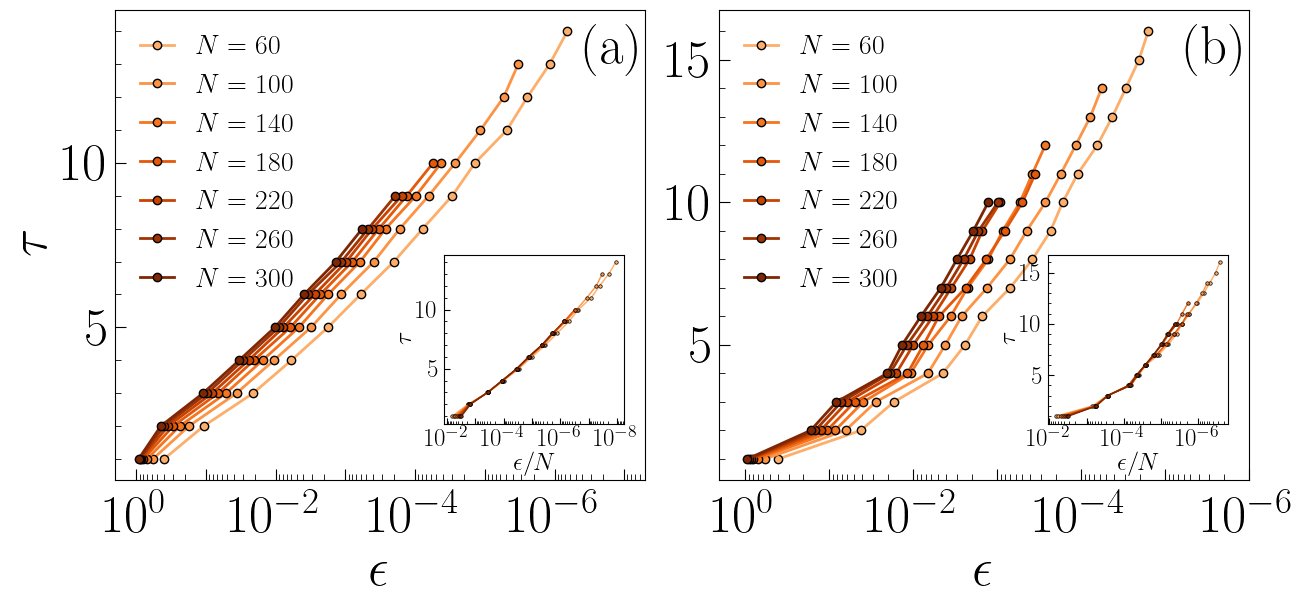

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(14, 7), layout="tight")
fig.get_layout_engine().set(w_pad=0.4)      # panels closer together (the default gap is in units of the 38pt font)

# (axis, data, extra decades of eps past the smallest error, panel label,
#  fraction of the height the data fill: < 1 leaves room above them for the label)
panels = [(axs[0], df_ising, 0.3, r"$\mathrm{(a)}$", 0.8),     # Ising g=0.75
          (axs[1], df_xxz,   1, r"$\mathrm{(b)}$", 1.0)]     # XXZ Jz=2.5
# connected two-site correlations of the N = 300 targets (connected_K.jl): K(r) = 4 ||rho_ij - rho_i rho_j||_2^2
# = sum_ab (<s^a_i s^b_j> - <s^a_i><s^b_j>)^2, sites symmetric about the centre; drawn in the insets at tau = r
Ks = [pd.read_csv(datapath + 'ising/g0.75/m5_long/K_N300.csv'), pd.read_csv(datapath + 'xxz/Jz2.5/m20_driver/K_N300.csv')]

for (ax, df, extra, label, fill), K in zip(panels, Ks):
    Ns = sorted(df.N.unique())
    cm = plt.cm.ScalarMappable(cmap="Oranges", norm=mpl.colors.Normalize(vmin=Ns[0] - 0.6*(Ns[-1] - Ns[0]), vmax=Ns[-1]))

    ax.set_xscale("log")
    ax.set_xlabel(r"$\epsilon$")
    if ax is axs[0]:                         # same tau axis label on both panels: only on the left one
        ax.set_ylabel(r"$\tau$")
    for N in Ns:
        d = df[df.N == N]
        ax.plot(d.err.values, d.tau.values, '-o', c=cm.to_rgba(N), mec='k', mew=1, lw=2, ms=6, label=f'$N={N}$')
    #if fill < 1:
        #lo = ax.get_ylim()[0]
        #ax.set_ylim(lo, lo + (df.tau.max() - lo) / fill)
    ax.text(1.0, 0.97, label, transform=ax.transAxes, ha='right', va='top')
    ax.legend(frameon=False, ncol=1, loc='upper left', fontsize=20, handlelength=1.2)
    # eps decreasing to the right (as in the Julia plots), ending `extra` decades past the smallest error
    ax.set_xlim(2, 10**(np.floor(np.log10(df.err.min())) - extra))
    style_ticks(ax, ymajor=5)
    ax.tick_params(axis='x', which='major', pad=12)      # x tick labels a bit lower
    ax.xaxis.set_major_formatter(even_decades)

    # inset: collapse in eps/N (the fit tau = A ln(N/eps) + c is printed by the cell above)
    ins = ax.inset_axes([0.62, 0.12, 0.34, 0.36])
    ins.set_xscale("log")
    ins.invert_xaxis()
    for N in Ns:
        d = df[df.N == N]
        ins.plot(d.err.values / N, d.tau.values, '-o', c=cm.to_rgba(N), mec='k', mew=0.5, lw=1, ms=2.5)
    xl, yl = ins.get_xlim(), ins.get_ylim()                     # keep the range of the data: K runs further
    ins.plot(K.K, K.r, 'k--', lw=1.2, label=r'$K$')
    ins.plot(np.sqrt(K.K), K.r, 'k:', lw=1.5, label=r'$\sqrt{K}$')
    ins.set_xlim(xl); ins.set_ylim(yl)
    ins.legend(frameon=False, fontsize=14, loc='upper left', handlelength=1.5, labelspacing=0.1, borderpad=0.1)
    ins.set_xlabel(r"$\epsilon/N$", fontsize=18, labelpad=0)
    ins.set_ylabel(r"$\tau$", fontsize=18, labelpad=0)
    style_ticks(ins, ymajor=5, labelsize=18, length=4)
    ins.xaxis.set_major_formatter(even_decades)

plt.savefig(resultspath + 'fig1.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'fig1.png', bbox_inches='tight', dpi=300)

In [6]:
# ---------------- Single-panel figures from invertTruncData copy.jl ----------------
# CSVs written there with extract_data_iters (df_iters.csv: error and |grad| of every depth after M iterations),
# extract_reltol_stops (df_reltol_stops.csv: where each depth would stop with err_reltol, replayed on the history)
# and extract_data (sequential runs).
xxz24 = datapath + 'xxz/Jz2.5/sweeps/chi24/parallel/'
it_xxz = {chi: pd.read_csv(datapath + f'xxz/Jz2.5/sweeps/chi{chi}/parallel/df_iters.csv') for chi in (24, 36, 48)}
st_xxz = pd.read_csv(xxz24 + 'df_reltol_stops.csv')
seq_xxz = pd.read_csv(datapath + 'xxz/Jz2.5/m20_driver/df.csv')
corr1 = datapath + 'corrmps/chi20/xi1.0/parallel/'
it_corr = pd.read_csv(corr1 + 'df_iters.csv')
st_corr = pd.read_csv(corr1 + 'df_reltol_stops.csv')
seq_corr = pd.read_csv(datapath + 'corrmps/chi20_long/xi1.0/df_N100.csv').sort_values('tau')
seq_corr['niter_cum'] = seq_corr.niter.cumsum()          # a sequential depth also pays for all the shallower ones
corr05 = datapath + 'corrmps/chi20/xi0.5/parallel/'
it_corr05 = pd.read_csv(corr05 + 'df_iters.csv')
st_corr05 = pd.read_csv(corr05 + 'df_reltol_stops.csv')
seq_corr05 = pd.read_csv(datapath + 'corrmps/chi20_long/xi0.5/df_N100.csv').sort_values('tau')
seq_corr05['niter_cum'] = seq_corr05.niter.cumsum()          # a sequential depth also pays for all the shallower ones
corr2 = datapath + 'corrmps/chi20/xi2.0/parallel/'
it_corr2 = pd.read_csv(corr2 + 'df_iters.csv')
st_corr2 = pd.read_csv(corr2 + 'df_reltol_stops.csv')
seq_corr2 = pd.read_csv(datapath + 'corrmps/chi20_long/xi2.0/df_N100.csv').sort_values('tau')
seq_corr2['niter_cum'] = seq_corr2.niter.cumsum()          # a sequential depth also pays for all the shallower ones

FIGSIZE = (7, 7)
MK = dict(mec='k', mew=1, lw=2, ms=5)

def sci_label(M):
    """1000 -> 10^3, 20000 -> 2 x 10^4"""
    e = int(np.floor(np.log10(M))); m = M / 10**e
    return rf'$10^{{{e}}}$' if m == 1 else rf'${m:g}\cdot 10^{{{e}}}$'

def tau_eps_axes(ax, ymajor=5):
    ax.set_xscale('log')
    ax.invert_xaxis()
    ax.set_xlabel(r'$\epsilon$')
    ax.set_ylabel(r'$\tau$')
    style_ticks(ax, ymajor=ymajor)
    ax.xaxis.set_major_formatter(even_decades)
    ax.tick_params(axis='x', which='major', pad=12)

def iter_tau_axes(ax):
    """tau on x (linear), iterations on y (log)"""
    ax.set_yscale('log')
    ax.set_xlabel(r'$\tau$')
    ax.set_ylabel(r'$M$')
    ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(5))
    ax.xaxis.set_minor_locator(mpl.ticker.MultipleLocator(1))
    ax.yaxis.set_major_locator(mpl.ticker.LogLocator(base=10, numticks=100))
    ax.yaxis.set_minor_locator(mpl.ticker.LogLocator(base=10, subs=np.arange(2, 10), numticks=100))
    ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax.tick_params(which='both', direction='in')
    ax.tick_params(which='major', length=8)
    ax.tick_params(which='minor', length=4)

def plot_iters(ax, d, Ms, cmap, ms=MK['ms'], lw=MK['lw'], label=True):
    """tau vs eps after M iterations, one curve per M (light = few iterations)"""
    shades = np.linspace(0.35, 0.95, len(Ms))
    for M, s in zip(Ms, shades):
        dm = d[d.M == M].sort_values('tau').dropna(subset=['err'])
        ax.plot(dm.err, dm.tau, '-o', c=cmap(s), mec='k', mew=1 if ms > 3 else 0.5, lw=lw, ms=ms,
                label=rf'$M={sci_label(M)[1:-1]}$' if label else None)

def plot_stops(ax, d, x, y, reltols, cmap):
    """err_reltol stops, one curve per reltol; depths that would not have stopped yet are hollow"""
    shades = np.linspace(0.35, 0.95, len(reltols))
    for r, s in zip(reltols, shades):
        dr = d[d.reltol == r].sort_values('tau')
        c = cmap(s)
        ax.plot(dr[x], dr[y], '-', c=c, lw=MK['lw'], label=rf'$r=10^{{{int(np.log10(r))}}}$')
        done = dr.stopped_by != 'not yet'
        ax.plot(dr[x][done], dr[y][done], 'o', c=c, mec='k', mew=1, ms=MK['ms'] + 1)
        ax.plot(dr[x][~done], dr[y][~done], 'o', mfc='white', mec=c, mew=1.5, ms=MK['ms'] + 1)

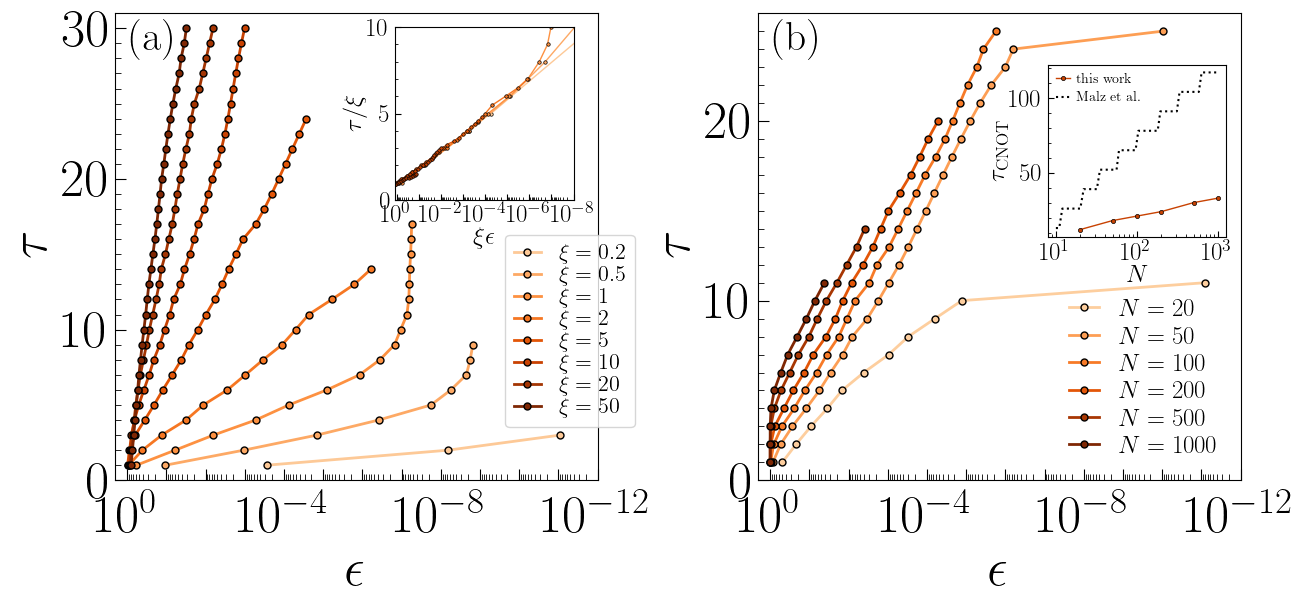

In [7]:
# corrmps, N = 100: tau vs eps for every xi; inset: tau/xi vs eps (the collapse)
# (style_ticks and even_decades are defined in the Ising/XXZ figure cell above)
N = 100
d_N = drop_wall(df_corr[df_corr.N == N])        # walls of the small xi removed
xis = sorted(d_N.xi.unique())
cm = plt.cm.ScalarMappable(cmap="Oranges", norm=mpl.colors.LogNorm(vmin=xis[0] / 8, vmax=xis[-1]))

# (a) tau vs eps for every xi; (b) xi = 4, tau vs eps for every N, inset: CNOT depth at F = 0.9 vs N
fig, (ax, ax_err) = plt.subplots(1, 2, figsize=(14, 7), layout="tight")
fig.get_layout_engine().set(w_pad=0)
ax.set_xscale("log")
ax.set_xlabel(r"$\epsilon$")
ax.set_ylabel(r"$\tau$")
for xi in xis:
    d = d_N[d_N.xi == xi]
    ax.plot(d.err.values, d.tau.values, '-o', c=cm.to_rgba(xi), mec='k', mew=1, lw=2, ms=5, label=rf'$\xi={xi:g}$')
# eps decreasing to the right; the axis goes well past the error floor of the small xi
# (vertical columns around 1e-10 ... 1e-7) to leave the right side free for the legend and the inset
ax.set_xlim(2, 1e-12)
ax.set_ylim(0, 31)
style_ticks(ax, ymajor=10)
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(
    lambda x, pos: rf'$10^{{{int(round(np.log10(x)))}}}$' if int(round(np.log10(x))) % 4 == 0 else ''))
ax.tick_params(axis='x', which='major', pad=12)
ax.legend(frameon=True, ncol=1, loc='lower right', bbox_to_anchor=(1.1, 0.09), fontsize=16, handlelength=1.2, labelspacing=0.1)

ins = ax.inset_axes([0.58, 0.6, 0.37, 0.37])
ins.set_xscale("log")
for xi in xis:
    d = d_N[d_N.xi == xi]
    ins.plot(xi * d.err.values, d.tau.values / xi, '-o', c=cm.to_rgba(xi), mec='k', mew=0.5, lw=1, ms=2.5)
ins.set_xlim(1.2, 1e-8)
ins.set_ylim(0, 10)
ins.set_xlabel(r"$\xi \epsilon$", fontsize=18, labelpad=0)
ins.set_ylabel(r"$\tau/\xi$", fontsize=18, labelpad=0)
style_ticks(ins, ymajor=5, labelsize=18, length=4)
ins.xaxis.set_major_formatter(even_decades)

# ---- (b): xi = 4, tau vs eps for every N (depths past numerical precision removed)
d4 = drop_noise(df_xi4)
Ns4 = sorted(d4.N.unique())
cmN = plt.cm.ScalarMappable(cmap="Oranges", norm=mpl.colors.LogNorm(vmin=Ns4[0] / 4, vmax=Ns4[-1]))
ax_err.set_xscale("log")
ax_err.set_xlabel(r"$\epsilon$")
ax_err.set_ylabel(r"$\tau$")
for N in Ns4:
    d = d4[d4.N == N]
    ax_err.plot(d.err.values, d.tau.values, '-o', c=cmN.to_rgba(N), mec='k', mew=1, lw=2, ms=5, label=f'$N={N}$')
ax_err.set_xlim(2, 1e-12)
ax_err.set_ylim(0, 26)                   # the inset sits above the tau = 25 points (N = 50, 100)
style_ticks(ax_err, ymajor=10)
ax_err.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(
    lambda x, pos: rf'$10^{{{int(round(np.log10(x)))}}}$' if int(round(np.log10(x))) % 4 == 0 else ''))
ax_err.tick_params(axis='x', which='major', pad=12)
ax_err.legend(frameon=False, ncol=1, loc='lower right', fontsize=18, handlelength=1.2,
              labelspacing=0.2, columnspacing=0.8)

# ---- inset of (b): CNOT depth to reach F = 0.9 (eps = 1 - sqrt(F)): 3 CNOTs per 2-qubit gate
#      layer of the brickwork, vs the sequential-RG estimate of Malz et al.
F = 0.9
eps_F = 1 - np.sqrt(F)
tau_F = [(N, d.tau.values[np.argmax(d.err.values < eps_F)]) for N, d in d4.groupby('N') if (d.err.values < eps_F).any()]
ax_cnot = ax_err.inset_axes([0.6, 0.52, 0.37, 0.37])      # bottom right, about square on screen
ax_cnot.set_xscale("log")
ax_cnot.set_xlabel(r"$N$", fontsize=18, labelpad=0)
ax_cnot.set_ylabel(r"$\tau_{\mathrm{CNOT}}$", fontsize=18, labelpad=0)
ax_cnot.plot([N for N, t in tau_F], [3 * t for N, t in tau_F], '-o', c=cmN.to_rgba(Ns4[-1] / 3), mec='k', mew=0.5, lw=1, ms=3,
             label=r'$\mathrm{this\ work}$')
ax_cnot.plot(df_malz.N.values, df_malz.T_cnot.values, ':', c='k', lw=1.5,
             label=r'$\mathrm{Malz\ et\ al.}$')
ax_cnot.xaxis.set_major_locator(mpl.ticker.LogLocator(base=10, numticks=100))
ax_cnot.xaxis.set_minor_locator(mpl.ticker.LogLocator(base=10, subs=np.arange(2, 10), numticks=100))
ax_cnot.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_cnot.yaxis.set_major_locator(mpl.ticker.MultipleLocator(50))
ax_cnot.yaxis.set_minor_locator(mpl.ticker.MultipleLocator(10))
ax_cnot.tick_params(which='both', direction='in', labelsize=18)
ax_cnot.tick_params(which='major', length=4)
ax_cnot.tick_params(which='minor', length=2)
ax_cnot.legend(frameon=False, loc='upper left', fontsize=10, handlelength=1.0, handletextpad=0.4,
               borderaxespad=0.2)     # between our curve and the staircase

# panel labels, in the top left corner of each panel
for a, lab in ((ax, '(a)'), (ax_err, '(b)')):
    a.text(0.03 if lab=='(a)' else 0.03, 0.9, rf'$\mathrm{{{lab}}}$', transform=a.transAxes, ha='left', va='bottom', fontsize=30)

plt.savefig(resultspath + 'fig2.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'fig2.png', bbox_inches='tight', dpi=300)

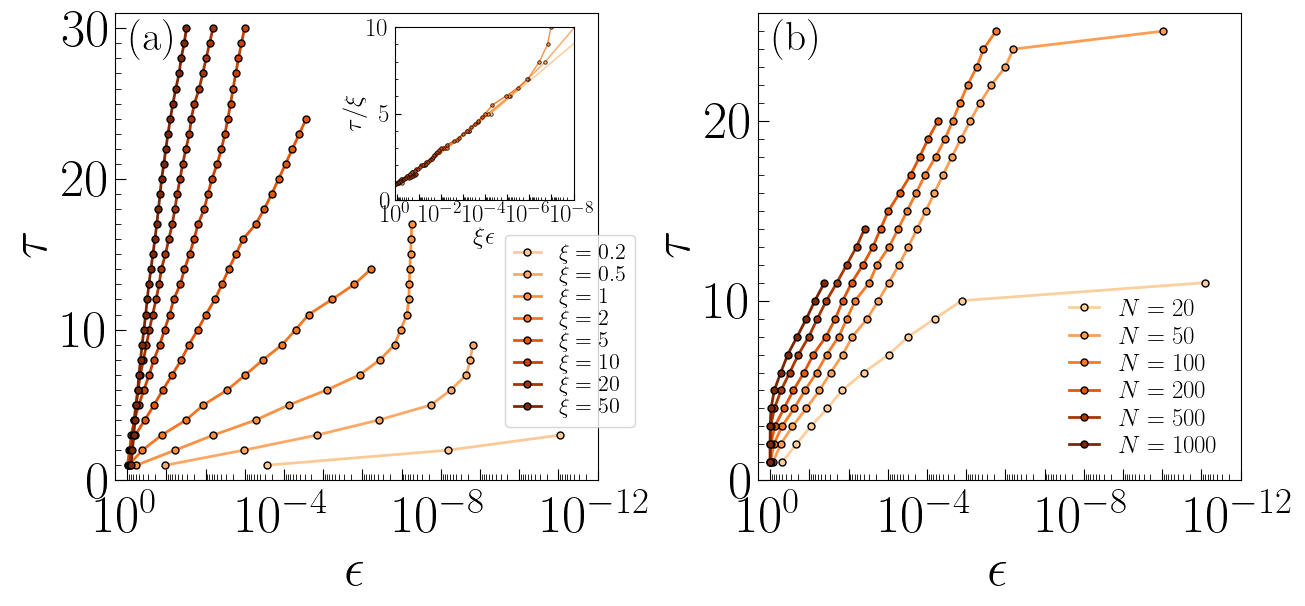

In [19]:
# corrmps, N = 100: tau vs eps for every xi; inset: tau/xi vs eps (the collapse)
# (style_ticks and even_decades are defined in the Ising/XXZ figure cell above)
N = 100
d_N = drop_wall(df_corr[df_corr.N == N])        # walls of the small xi removed
xis = sorted(d_N.xi.unique())
cm = plt.cm.ScalarMappable(cmap="Oranges", norm=mpl.colors.LogNorm(vmin=xis[0] / 8, vmax=xis[-1]))

# (a) tau vs eps for every xi; (b) xi = 4, tau vs eps for every N, inset: CNOT depth at F = 0.9 vs N
fig, (ax, ax_err) = plt.subplots(1, 2, figsize=(14, 7), layout="tight")
fig.get_layout_engine().set(w_pad=0)
ax.set_xscale("log")
ax.set_xlabel(r"$\epsilon$")
ax.set_ylabel(r"$\tau$")
for xi in xis:
    d = d_N[d_N.xi == xi]
    ax.plot(d.err.values, d.tau.values, '-o', c=cm.to_rgba(xi), mec='k', mew=1, lw=2, ms=5, label=rf'$\xi={xi:g}$')
# eps decreasing to the right; the axis goes well past the error floor of the small xi
# (vertical columns around 1e-10 ... 1e-7) to leave the right side free for the legend and the inset
ax.set_xlim(2, 1e-12)
ax.set_ylim(0, 31)
style_ticks(ax, ymajor=10)
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(
    lambda x, pos: rf'$10^{{{int(round(np.log10(x)))}}}$' if int(round(np.log10(x))) % 4 == 0 else ''))
ax.tick_params(axis='x', which='major', pad=12)
ax.legend(frameon=True, ncol=1, loc='lower right', bbox_to_anchor=(1.1, 0.09), fontsize=16, handlelength=1.2, labelspacing=0.1)

ins = ax.inset_axes([0.58, 0.6, 0.37, 0.37])
ins.set_xscale("log")
for xi in xis:
    d = d_N[d_N.xi == xi]
    ins.plot(xi * d.err.values, d.tau.values / xi, '-o', c=cm.to_rgba(xi), mec='k', mew=0.5, lw=1, ms=2.5)
ins.set_xlim(1.2, 1e-8)
ins.set_ylim(0, 10)
ins.set_xlabel(r"$\xi \epsilon$", fontsize=18, labelpad=0)
ins.set_ylabel(r"$\tau/\xi$", fontsize=18, labelpad=0)
style_ticks(ins, ymajor=5, labelsize=18, length=4)
ins.xaxis.set_major_formatter(even_decades)

# ---- (b): xi = 4, tau vs eps for every N (depths past numerical precision removed)
d4 = drop_noise(df_xi4)
Ns4 = sorted(d4.N.unique())
cmN = plt.cm.ScalarMappable(cmap="Oranges", norm=mpl.colors.LogNorm(vmin=Ns4[0] / 4, vmax=Ns4[-1]))
ax_err.set_xscale("log")
ax_err.set_xlabel(r"$\epsilon$")
ax_err.set_ylabel(r"$\tau$")
for N in Ns4:
    d = d4[d4.N == N]
    ax_err.plot(d.err.values, d.tau.values, '-o', c=cmN.to_rgba(N), mec='k', mew=1, lw=2, ms=5, label=f'$N={N}$')
ax_err.set_xlim(2, 1e-12)
ax_err.set_ylim(0, 26)                   # the inset sits above the tau = 25 points (N = 50, 100)
style_ticks(ax_err, ymajor=10)
ax_err.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(
    lambda x, pos: rf'$10^{{{int(round(np.log10(x)))}}}$' if int(round(np.log10(x))) % 4 == 0 else ''))
ax_err.tick_params(axis='x', which='major', pad=12)
ax_err.legend(frameon=False, ncol=1, loc='lower right', fontsize=18, handlelength=1.2,
              labelspacing=0.2, columnspacing=0.8)


# panel labels, in the top left corner of each panel
for a, lab in ((ax, '(a)'), (ax_err, '(b)')):
    a.text(0.03 if lab=='(a)' else 0.03, 0.9, rf'$\mathrm{{{lab}}}$', transform=a.transAxes, ha='left', va='bottom', fontsize=30)

plt.savefig(resultspath + 'fig2_noinset.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'fig2_noinset.png', bbox_inches='tight', dpi=300)

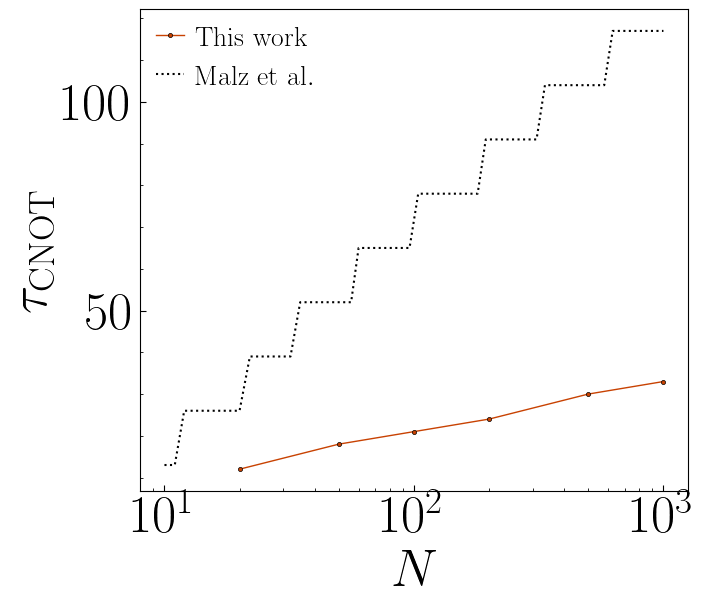

In [25]:
# corrmps, N = 100: tau vs eps for every xi; inset: tau/xi vs eps (the collapse)
# (style_ticks and even_decades are defined in the Ising/XXZ figure cell above)
N = 100
d_N = drop_wall(df_corr[df_corr.N == N])        # walls of the small xi removed
xis = sorted(d_N.xi.unique())
cm = plt.cm.ScalarMappable(cmap="Oranges", norm=mpl.colors.LogNorm(vmin=xis[0] / 8, vmax=xis[-1]))

# (a) tau vs eps for every xi; (b) xi = 4, tau vs eps for every N, inset: CNOT depth at F = 0.9 vs N
fig, ax = plt.subplots(1, 1, figsize=FIGSIZE, layout="tight")


# ---- (b): xi = 4, tau vs eps for every N (depths past numerical precision removed)
d4 = drop_noise(df_xi4)
Ns4 = sorted(d4.N.unique())
cmN = plt.cm.ScalarMappable(cmap="Oranges", norm=mpl.colors.LogNorm(vmin=Ns4[0] / 4, vmax=Ns4[-1]))


# ---- inset of (b): CNOT depth to reach F = 0.9 (eps = 1 - sqrt(F)): 3 CNOTs per 2-qubit gate
#      layer of the brickwork, vs the sequential-RG estimate of Malz et al.
F = 0.9
eps_F = 1 - np.sqrt(F)
tau_F = [(N, d.tau.values[np.argmax(d.err.values < eps_F)]) for N, d in d4.groupby('N') if (d.err.values < eps_F).any()]
ax_cnot = ax      # bottom right, about square on screen
ax_cnot.set_xscale("log")
ax_cnot.set_xlabel(r"$N$")
ax_cnot.set_ylabel(r"$\tau_{\mathrm{CNOT}}$")
ax_cnot.plot([N for N, t in tau_F], [3 * t for N, t in tau_F], '-o', c=cmN.to_rgba(Ns4[-1] / 3), mec='k', mew=0.5, lw=1, ms=3,
             label=r'$\mathrm{This\ work}$')
ax_cnot.plot(df_malz.N.values, df_malz.T_cnot.values, ':', c='k', lw=1.5,
             label=r'$\mathrm{Malz\ et\ al.}$')
ax_cnot.xaxis.set_major_locator(mpl.ticker.LogLocator(base=10, numticks=100))
ax_cnot.xaxis.set_minor_locator(mpl.ticker.LogLocator(base=10, subs=np.arange(2, 10), numticks=100))
ax_cnot.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_cnot.yaxis.set_major_locator(mpl.ticker.MultipleLocator(50))
ax_cnot.yaxis.set_minor_locator(mpl.ticker.MultipleLocator(10))
ax_cnot.tick_params(which='both', direction='in')
ax_cnot.tick_params(which='major', length=4)
ax_cnot.tick_params(which='minor', length=2)
ax_cnot.legend(frameon=False, loc='upper left', fontsize=20, handlelength=1.0, handletextpad=0.4,
               borderaxespad=0.2)     # between our curve and the staircase

# panel labels, in the top left corner of each panel
#for a, lab in ((ax, '(a)'), (ax_err, '(b)')):
#    a.text(0.03 if lab=='(a)' else 0.03, 0.9, rf'$\mathrm{{{lab}}}$', transform=a.transAxes, ha='left', va='bottom', fontsize=30)

plt.savefig(resultspath + 'fig2c.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'fig2c.png', bbox_inches='tight', dpi=300)

common exponent p = 1.39
  Ising g=0.75   w1000 = 1.08e-05
  XXZ Jz=2.5     w1000 = 7.16e-06
  XXZ Jz=10      w1000 = 1.36e-07
  XXZ Jz=20      w1000 = 1.82e-08
  corr xi=0.5    w1000 = 6.55e-09
  corr xi=1      w1000 = 5.69e-07
  corr xi=2      w1000 = 9.09e-06


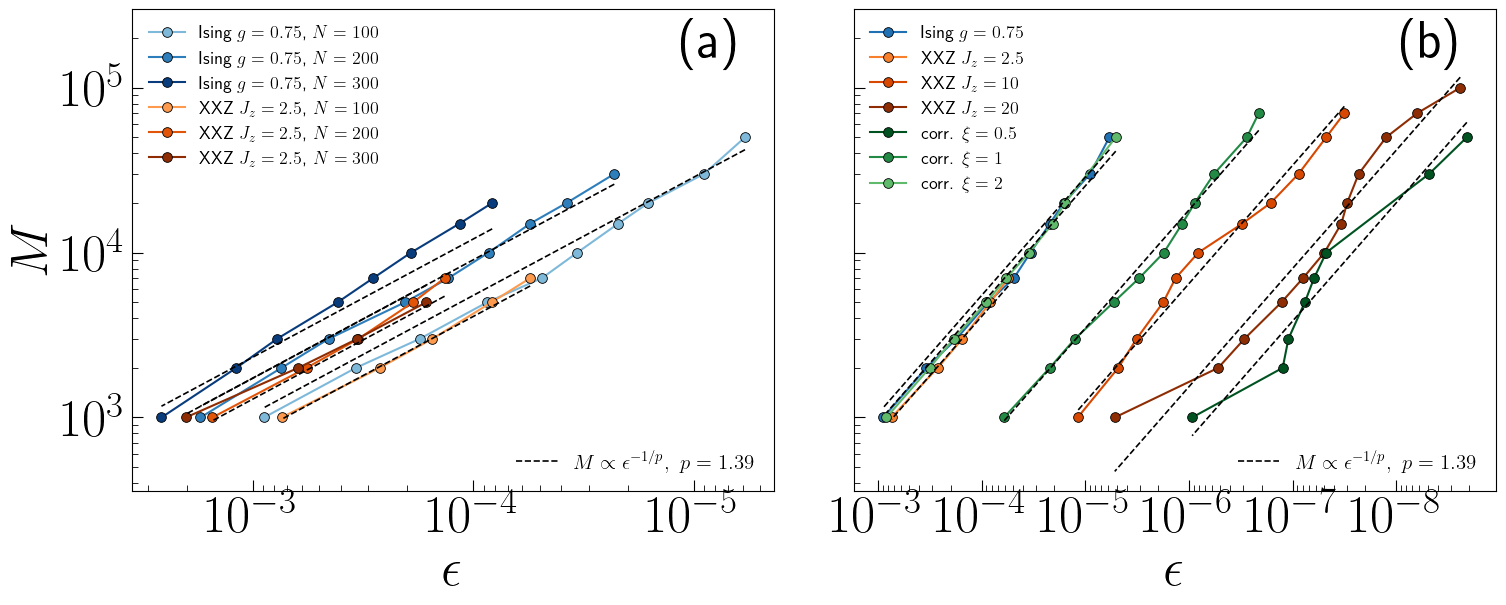

In [6]:
# Iterations M needed to reach an error eps with a deep (non-saturated) circuit.
# wall_budget.csv (from wall_export.jl): for each family and N, the median error over depths tau = 15..28
# of the parallel runs after M iterations ("wall"), its max/min spread over those depths, and how many depths reached M.
# Model: eps = N * w_f * (M/1000)^(-p)  <=>  M = 1000 * (w_f N/eps)^(1/p),
# one exponent p shared by all families, one prefactor w_f (error per site after 1000 iterations) per family.
dfw = pd.read_csv(datapath + 'wall_budget.csv')
dfw = dfw[(dfw.M >= 1000) & (dfw.spread <= 3) & (dfw.ndepths >= 10)].copy()   # past the transient, before saturation
dfw['x'] = dfw.N / dfw.wall

fams = [f for f in dict.fromkeys(dfw.family) if f != 'XXZ Jz=50']   # Jz=50 has a steeper tail (own p ~ 2)
dfw = dfw[dfw.family.isin(fams)]
X = np.zeros((len(dfw), 1 + len(fams)))
X[:, 0] = np.log(dfw.x.values)
for k, f in enumerate(fams):
    X[:, 1 + k] = (dfw.family.values == f)
c, *_ = np.linalg.lstsq(X, np.log(dfw.M.values), rcond=None)
p_fit = 1 / c[0]
w1000 = {f: np.exp((c[1 + k] - np.log(1000)) * p_fit) for k, f in enumerate(fams)}
Mfit = lambda w, N, eps: 1000 * (w * N / eps) ** (1 / p_fit)
print(f'common exponent p = {p_fit:.2f}')
for f in fams:
    print(f'  {f:14s} w1000 = {w1000[f]:.2e}')

labels = {'Ising g=0.75': r'Ising $g=0.75$', 'XXZ Jz=2.5': r'XXZ $J_z=2.5$', 'XXZ Jz=10': r'XXZ $J_z=10$',
          'XXZ Jz=20': r'XXZ $J_z=20$', 'corr xi=0.5': r'corr. $\xi=0.5$', 'corr xi=1': r'corr. $\xi=1$',
          'corr xi=2': r'corr. $\xi=2$'}
Ns = [100, 200, 300]
shade = dict(zip(Ns, [0.45, 0.7, 0.95]))
col_N = {'Ising g=0.75': lambda N: plt.cm.Blues(shade[N]), 'XXZ Jz=2.5': lambda N: plt.cm.Oranges(shade[N])}
col_f = {'Ising g=0.75': plt.cm.Blues(0.75), 'XXZ Jz=2.5': plt.cm.Oranges(0.55), 'XXZ Jz=10': plt.cm.Oranges(0.75),
         'XXZ Jz=20': plt.cm.Oranges(0.95), 'corr xi=0.5': plt.cm.Greens(0.95), 'corr xi=1': plt.cm.Greens(0.75),
         'corr xi=2': plt.cm.Greens(0.55)}



fig, axs = plt.subplots(1, 2, figsize=(16, 7), layout="tight", sharey=True)
# (a) families with three N
for f in ('Ising g=0.75', 'XXZ Jz=2.5'):
    for N in Ns:
        g = dfw[(dfw.family == f) & (dfw.N == N)]
        curve(axs[0], g, col_N[f](N), label=labels[f] + rf', $N={N}$')
        fitline(axs[0], g, w1000[f], N)
# (b) all families at N = 100
for f in fams:
    g = dfw[(dfw.family == f) & (dfw.N == 100)]
    curve(axs[1], g, col_f[f], label=labels[f])
    fitline(axs[1], g, w1000[f], 100)

fit_label = rf'$M \propto \epsilon^{{-1/p}},\ p={p_fit:.2f}$'
for ax in axs:
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.invert_xaxis()
    ax.set_xlabel(r'$\epsilon$')
    log_ticks(ax)
    ax.add_artist(ax.legend(frameon=False, fontsize=13, loc='upper left'))
    fl, = ax.plot([], [], 'k--', lw=1.2)
    ax.legend([fl], [fit_label], frameon=False, fontsize=15, loc='lower right')
axs[0].set_ylabel(r'$M$')
axs[0].set_ylim(top=3e5)                                   # headroom for the legends
for ax, l in zip(axs, ('(a)', '(b)')):
    ax.text(0.95, 0.9, l, transform=ax.transAxes, ha='right')
plt.subplots_adjust(wspace=0.05)
plt.savefig(resultspath + 'iterations_vs_eps.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'iterations_vs_eps.png', bbox_inches='tight', dpi=300)

(1) limiting curve: tau = 0.247 exp(1.282 sqrt(ln(1/eps)))  (converged tau = 2..8)
(1) M = 100000: tau = 1.19 eps^-0.258   =>   eps ~ tau^-3.87


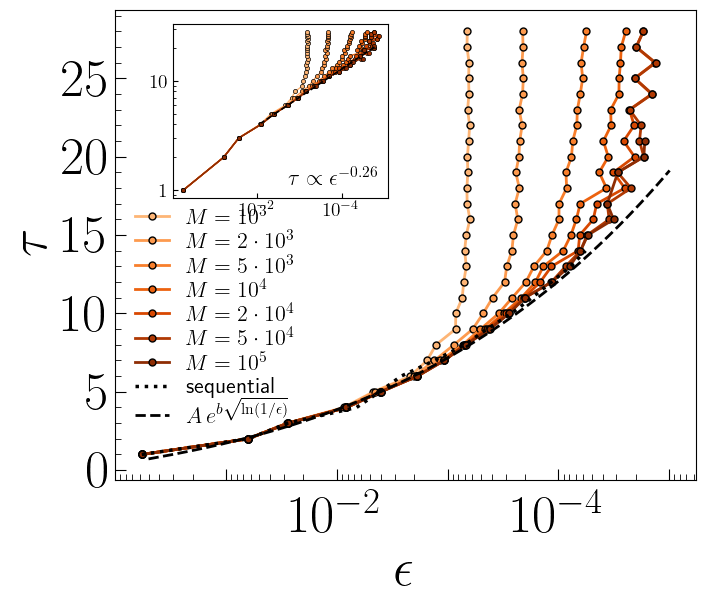

In [ ]:
# (1) XXZ Jz=2.5, chi=24, N=100, parallel: tau vs eps after M iterations, sequential run dotted.
# Dashed: limiting curve tau = A exp(b sqrt(ln(1/eps))), fitted on the converged depths (tau >= 2),
# the form suggested by the truncation scaling chi ~ exp(c sqrt(ln(N/eps))) of the XXZ ground states.
# Inset: same in log-log, power law tau = A eps^alpha fitted at the largest M (depths tau >= 4).
# Every depth ran at least 70999 iterations, so all curves are complete up to M = 70000.
N = 100
Ms = [1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000]
d = it_xxz[24][it_xxz[24].N == N]
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
plot_iters(ax, d, Ms, plt.cm.Oranges)
s = seq_xxz[seq_xxz.N == N].sort_values('tau')
ax.plot(s.err, s.tau, 'k:', lw=2.5, label='sequential')
dc = d[(d.M == Ms[-1]) & d.converged & (d.tau >= 2)]
b_lim, logA_lim = np.polyfit(np.sqrt(np.log(1 / dc.err)), np.log(dc.tau), 1)
print(f'(1) limiting curve: tau = {np.exp(logA_lim):.3f} exp({b_lim:.3f} sqrt(ln(1/eps)))  (converged tau = {dc.tau.min()}..{dc.tau.max()})')
eps_lim = np.geomspace(0.5, d.err.min(), 200)
ax.plot(eps_lim, np.exp(logA_lim + b_lim * np.sqrt(np.log(1 / eps_lim))), 'k--', lw=2, zorder=5,
        label=r'$A\,e^{b\sqrt{\ln(1/\epsilon)}}$')
tau_eps_axes(ax)
#ax.set_ylim(0, 38)                                  # headroom for the two-column legend
ax.legend(frameon=False, fontsize=16, loc='lower left', 
          handlelength=1.5, labelspacing=0.2, ncol=1, 
          columnspacing=0.8, bbox_to_anchor=(0, 0.07))

ins = ax.inset_axes([0.1, 0.6, 0.37, 0.37])          # the empty region above the shallow depths
plot_iters(ins, d, Ms, plt.cm.Oranges, ms=3, lw=1, label=False)
dm = d[(d.M == Ms[-1]) & (d.tau >= 4)].dropna(subset=['err'])
alpha, logA = np.polyfit(np.log(dm.err), np.log(dm.tau), 1)
print(f'(1) M = {Ms[-1]}: tau = {np.exp(logA):.3g} eps^{alpha:.3f}   =>   eps ~ tau^{1/alpha:.2f}')
xs = np.geomspace(dm.err.min(), dm.err.max(), 50)
ins.plot(xs, np.exp(logA) * xs ** alpha, 'k--', lw=1.2)
ins.text(0.95, 0.05, rf'$\tau\propto\epsilon^{{{alpha:.2f}}}$', transform=ins.transAxes, ha='right', va='bottom', fontsize=16)
ins.set_xscale('log'); ins.set_yscale('log'); ins.invert_xaxis()
ins.tick_params(which='both', direction='in', labelsize=14)
ins.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ins.set_yticks([1, 10]); ins.set_yticklabels([r'$1$', r'$10$'])
plt.savefig(resultspath + 'xxz_chi24_iters.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'xxz_chi24_iters.png', bbox_inches='tight', dpi=300)

(1) limiting curve: tau = 0.247 exp(1.282 sqrt(ln(1/eps)))  (converged tau = 2..8)


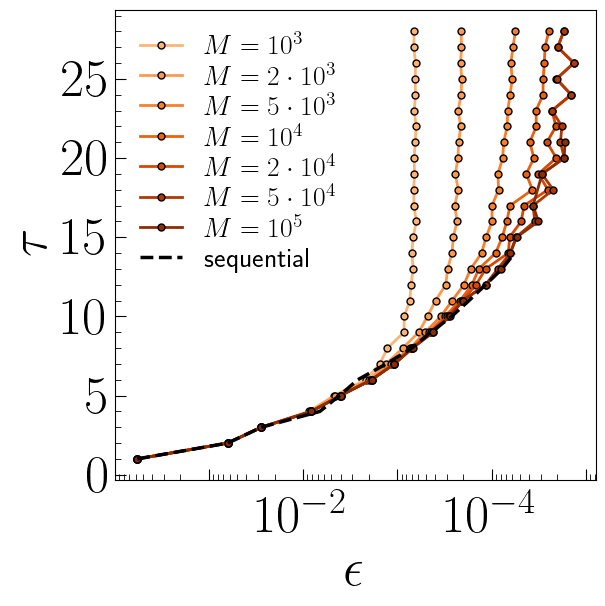

In [9]:
# (1) XXZ Jz=2.5, chi=24, N=100, parallel: tau vs eps after M iterations, sequential run dotted.
# Dashed: limiting curve tau = A exp(b sqrt(ln(1/eps))), fitted on the converged depths (tau >= 2),
# the form suggested by the truncation scaling chi ~ exp(c sqrt(ln(N/eps))) of the XXZ ground states.
# Inset: same in log-log, power law tau = A eps^alpha fitted at the largest M (depths tau >= 4).
# Every depth ran at least 70999 iterations, so all curves are complete up to M = 70000.
N = 100
Ms = [1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000]
d = it_xxz[24][it_xxz[24].N == N]
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
plot_iters(ax, d, Ms, plt.cm.Oranges)
s = seq_xxz[seq_xxz.N == N].sort_values('tau')
ax.plot(s.err, s.tau, 'k--', lw=2.5, label='sequential')
dc = d[(d.M == Ms[-1]) & d.converged & (d.tau >= 2)]
b_lim, logA_lim = np.polyfit(np.sqrt(np.log(1 / dc.err)), np.log(dc.tau), 1)
print(f'(1) limiting curve: tau = {np.exp(logA_lim):.3f} exp({b_lim:.3f} sqrt(ln(1/eps)))  (converged tau = {dc.tau.min()}..{dc.tau.max()})')
eps_lim = np.geomspace(0.5, d.err.min(), 200)

tau_eps_axes(ax)
#ax.set_ylim(0, 38)                                  # headroom for the two-column legend
ax.legend(frameon=False, fontsize=20, loc='upper left', 
          handlelength=1.5, labelspacing=0.2, ncol=1, 
          columnspacing=0.8, 
          #bbox_to_anchor=(0, 0.07)
          )


plt.savefig(resultspath + 'xxz_chi24_iters.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'xxz_chi24_iters.png', bbox_inches='tight', dpi=300)

(1) limiting curve: tau = 0.355 exp(1.207 sqrt(ln(1/eps)))  (converged tau = 2..7)


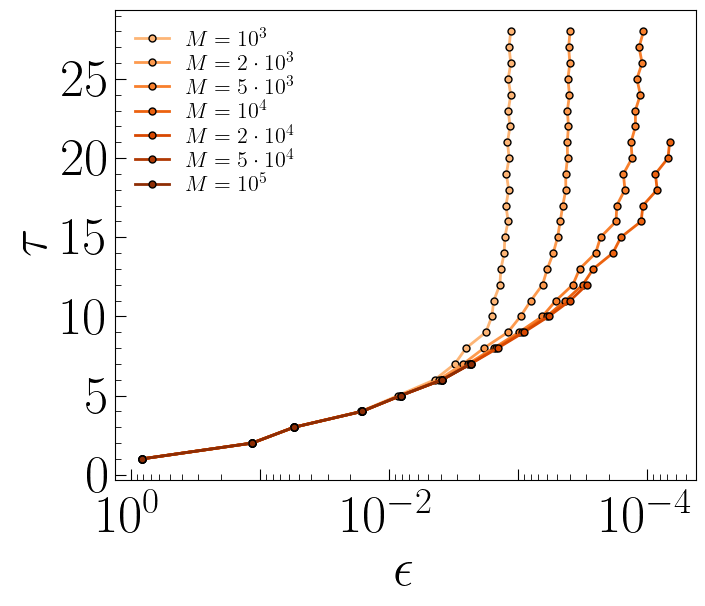

In [16]:
# (1) XXZ Jz=2.5, chi=24, N=100, parallel: tau vs eps after M iterations, sequential run dotted.
# Dashed: limiting curve tau = A exp(b sqrt(ln(1/eps))), fitted on the converged depths (tau >= 2),
# the form suggested by the truncation scaling chi ~ exp(c sqrt(ln(N/eps))) of the XXZ ground states.
# Inset: same in log-log, power law tau = A eps^alpha fitted at the largest M (depths tau >= 4).
# Every depth ran at least 70999 iterations, so all curves are complete up to M = 70000.
N = 200
Ms = [1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000]
d = it_xxz[24][it_xxz[24].N == N]
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
plot_iters(ax, d, Ms, plt.cm.Oranges)
s = seq_xxz[seq_xxz.N == N].sort_values('tau')
#ax.plot(s.err, s.tau, 'k--', lw=2.5, label='sequential')
dc = d[(d.M == Ms[-1]) & d.converged & (d.tau >= 2)]
b_lim, logA_lim = np.polyfit(np.sqrt(np.log(1 / dc.err)), np.log(dc.tau), 1)
print(f'(1) limiting curve: tau = {np.exp(logA_lim):.3f} exp({b_lim:.3f} sqrt(ln(1/eps)))  (converged tau = {dc.tau.min()}..{dc.tau.max()})')
eps_lim = np.geomspace(0.5, d.err.min(), 200)

tau_eps_axes(ax)
#ax.set_ylim(0, 38)                                  # headroom for the two-column legend
ax.legend(frameon=False, fontsize=16, loc='upper left', 
          handlelength=1.5, labelspacing=0.2, ncol=1, 
          columnspacing=0.8, 
          #bbox_to_anchor=(0, 0.07)
          )


plt.savefig(resultspath + 'xxz_N200_chi24_iters.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'xxz_N200_chi24_iters.png', bbox_inches='tight', dpi=300)

(1) limiting curve: tau = 0.430 exp(1.173 sqrt(ln(1/eps)))  (converged tau = 2..7)


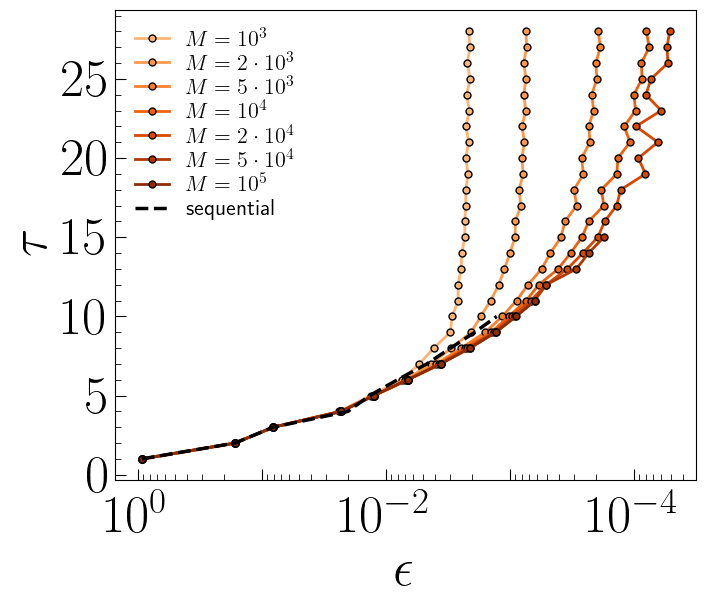

In [17]:
# (1) XXZ Jz=2.5, chi=24, N=100, parallel: tau vs eps after M iterations, sequential run dotted.
# Dashed: limiting curve tau = A exp(b sqrt(ln(1/eps))), fitted on the converged depths (tau >= 2),
# the form suggested by the truncation scaling chi ~ exp(c sqrt(ln(N/eps))) of the XXZ ground states.
# Inset: same in log-log, power law tau = A eps^alpha fitted at the largest M (depths tau >= 4).
# Every depth ran at least 70999 iterations, so all curves are complete up to M = 70000.
N = 300
Ms = [1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000]
d = it_xxz[24][it_xxz[24].N == N]
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
plot_iters(ax, d, Ms, plt.cm.Oranges)
s = seq_xxz[seq_xxz.N == N].sort_values('tau')
ax.plot(s.err, s.tau, 'k--', lw=2.5, label='sequential')
dc = d[(d.M == Ms[-1]) & d.converged & (d.tau >= 2)]
b_lim, logA_lim = np.polyfit(np.sqrt(np.log(1 / dc.err)), np.log(dc.tau), 1)
print(f'(1) limiting curve: tau = {np.exp(logA_lim):.3f} exp({b_lim:.3f} sqrt(ln(1/eps)))  (converged tau = {dc.tau.min()}..{dc.tau.max()})')
eps_lim = np.geomspace(0.5, d.err.min(), 200)

tau_eps_axes(ax)
#ax.set_ylim(0, 38)                                  # headroom for the two-column legend
ax.legend(frameon=False, fontsize=16, loc='upper left', 
          handlelength=1.5, labelspacing=0.2, ncol=1, 
          columnspacing=0.8, 
          #bbox_to_anchor=(0, 0.07)
          )


plt.savefig(resultspath + 'xxz_N300_chi24_iters.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'xxz_N300_chi24_iters.png', bbox_inches='tight', dpi=300)

(1) M = 100000: tau = 1.46 eps^-0.272   =>   eps ~ tau^-3.68


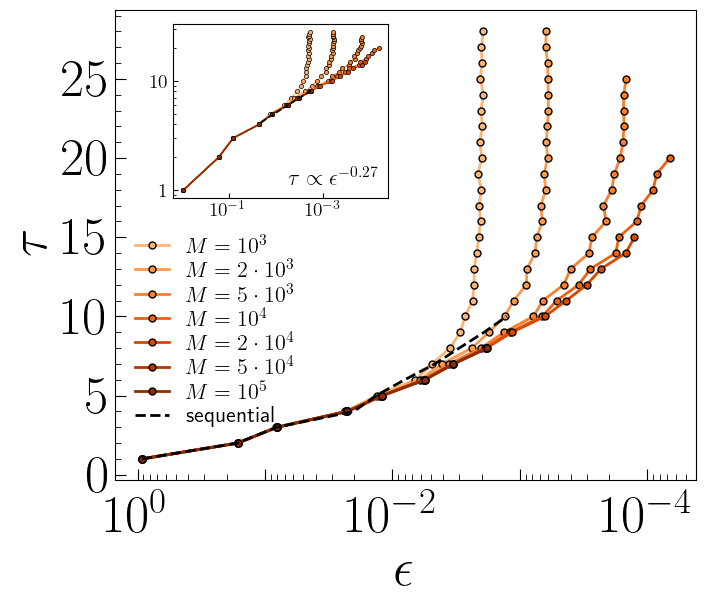

In [ ]:
# (1) XXZ Jz=2.5, chi=36, N=100, parallel: tau vs eps after M iterations, sequential run dashed.
# Inset: same in log-log, power law tau = A eps^alpha fitted at the largest M (depths tau >= 4).
# Every depth ran at least 70999 iterations, so all curves are complete up to M = 70000.
N = 300
Ms = [1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000]
d = it_xxz[36][it_xxz[36].N == N]
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
plot_iters(ax, d, Ms, plt.cm.Oranges)
s = seq_xxz[seq_xxz.N == N].sort_values('tau')
ax.plot(s.err, s.tau, 'k--', lw=2, label='sequential')
tau_eps_axes(ax)
#ax.set_ylim(0, 38)                                  # headroom for the two-column legend
ax.legend(frameon=False, fontsize=16, loc='lower left', 
          handlelength=1.5, labelspacing=0.2, ncol=1, 
          columnspacing=0.8, bbox_to_anchor=(0, 0.07))

ins = ax.inset_axes([0.1, 0.6, 0.37, 0.37])          # the empty region above the shallow depths
plot_iters(ins, d, Ms, plt.cm.Oranges, ms=3, lw=1, label=False)
dm = d[(d.M == Ms[-1]) & (d.tau >= 4)].dropna(subset=['err'])
alpha, logA = np.polyfit(np.log(dm.err), np.log(dm.tau), 1)
print(f'(1) M = {Ms[-1]}: tau = {np.exp(logA):.3g} eps^{alpha:.3f}   =>   eps ~ tau^{1/alpha:.2f}')
xs = np.geomspace(dm.err.min(), dm.err.max(), 50)
ins.plot(xs, np.exp(logA) * xs ** alpha, 'k--', lw=1.2)
ins.text(0.95, 0.05, rf'$\tau\propto\epsilon^{{{alpha:.2f}}}$', transform=ins.transAxes, ha='right', va='bottom', fontsize=16)
ins.set_xscale('log'); ins.set_yscale('log'); ins.invert_xaxis()
ins.tick_params(which='both', direction='in', labelsize=14)
ins.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ins.set_yticks([1, 10]); ins.set_yticklabels([r'$1$', r'$10$'])
plt.savefig(resultspath + 'xxz_chi36_iters.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'xxz_chi36_iters.png', bbox_inches='tight', dpi=300)

In [ ]:
# (1c) XXZ Jz=2.5, chi=36, N=100, parallel: tau vs eps after M iterations, with the connected two-site correlations
# K(r) = 4 ||rho_ij - rho_i rho_j||_2^2 of the target (connected_K.jl, averaged over two neighbouring central pairs)
# drawn at tau = r as eps = N K (dashed) and N sqrt(K) (dotted): the same comparison as in the fig1 insets (eps/N vs K).
N = 100
Ms = [1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000]
d = it_xxz[36][it_xxz[36].N == N]
K = pd.read_csv(datapath + f'xxz/Jz2.5/sweeps/chi36/K_N{N}.csv')
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
plot_iters(ax, d, Ms, plt.cm.Oranges)
tau_eps_axes(ax)
xl, yl = ax.get_xlim(), ax.get_ylim()                      # keep the range of the data: K runs further
ax.plot(N * K.K, K.r, 'k--', lw=1.5, label=r'$NK$')
ax.plot(N * np.sqrt(K.K), K.r, 'k:', lw=2, label=r'$N\sqrt{K}$')
ax.set_xlim(xl); ax.set_ylim(yl)
ax.legend(frameon=False, fontsize=16, loc='upper left', handlelength=1.5, labelspacing=0.2)
plt.savefig(resultspath + f'xxz_chi36_K_N{N}.pdf', bbox_inches='tight')
plt.savefig(resultspath + f'xxz_chi36_K_N{N}.png', bbox_inches='tight', dpi=300)


In [ ]:
# (2a) XXZ Jz=2.5, chi=24, N=100: tau vs eps where each depth would stop with err_reltol = r
# (relative decrease of the error over the last 1000 iterations below r), replayed on the err_reltol = 0 runs.
reltols = [1e-1, 1e-2, 1e-3, 1e-4]
d = st_xxz[st_xxz.N == N]
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
plot_stops(ax, d, 'err_stop', 'tau', reltols, plt.cm.Oranges)
tau_eps_axes(ax)
ax.set_ylim(0, 30)
ax.legend(frameon=False, fontsize=16, loc='upper left', handlelength=1.5, labelspacing=0.2)
plt.savefig(resultspath + 'xxz_chi24_reltol_err.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'xxz_chi24_reltol_err.png', bbox_inches='tight', dpi=300)

# (2b) iterations at which each depth stops
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
plot_stops(ax, d, 'tau', 'stop_iter', reltols, plt.cm.Oranges)
iter_tau_axes(ax)
ax.legend(frameon=False, fontsize=16, loc='lower right', handlelength=1.5, labelspacing=0.2)
plt.savefig(resultspath + 'xxz_chi24_reltol_iters.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'xxz_chi24_reltol_iters.png', bbox_inches='tight', dpi=300)

(3) chi=24: 28 depths at M=50000
(3) chi=36: 28 depths at M=50000
(3) chi=48: 20 depths at M=50000


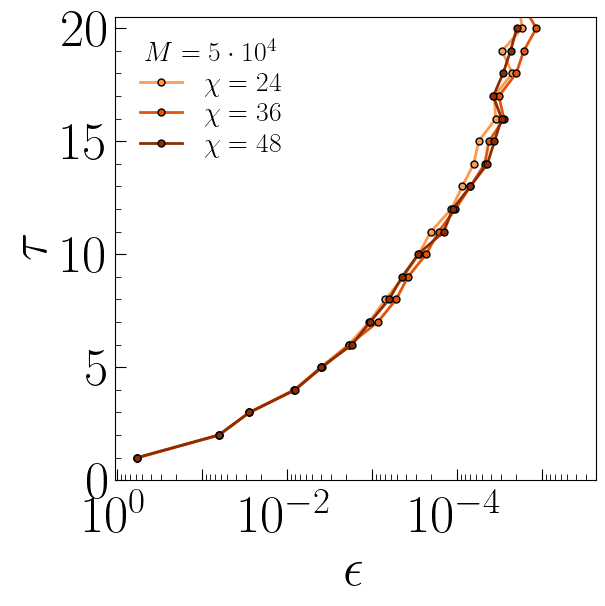

In [14]:
# (3) XXZ Jz=2.5, N=100: chi = 24, 36, 48 compared at the same number of iterations.
# The shortest histories are ~32000 iterations (chi=36 and 48 at tau=28), so M = 30000.
N = 100
M = 50_000
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
for chi, s in zip((24, 36, 48), (0.45, 0.7, 0.95)):
    d = it_xxz[chi][(it_xxz[chi].N == N) & (it_xxz[chi].M == M)].sort_values('tau').dropna(subset=['err'])
    ax.plot(d.err, d.tau, '-o', c=plt.cm.Oranges(s), **MK, label=rf'$\chi={chi}$')
    print(f'(3) chi={chi}: {len(d)} depths at M={M}')
tau_eps_axes(ax)
ax.set_ylim(0, 20.5)
ax.legend(frameon=False, fontsize=20, loc='upper left', handlelength=1.5, labelspacing=0.2,
          title=rf'$M={sci_label(M)[1:-1]}$', title_fontsize=20)
plt.savefig(resultspath + 'xxz_chi_compare.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'xxz_chi_compare.png', bbox_inches='tight', dpi=300)

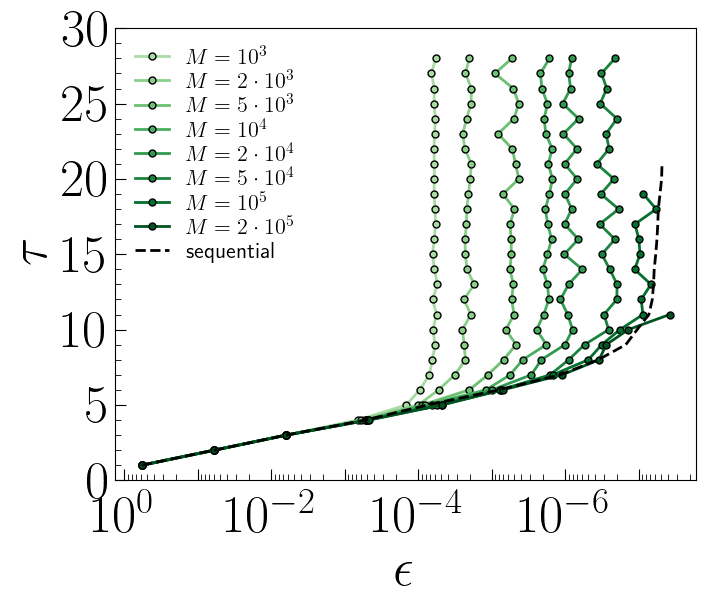

In [ ]:
# (4) corrmps xi=1, chi=20, N=100, parallel: tau vs eps after M iterations, sequential (chi20_long) dashed.
# Every depth ran at least 61999 iterations: curves complete up to M = 60000.
N = 100
Ms = [1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000, 200_000]
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
plot_iters(ax, it_corr[it_corr.N == N], Ms, plt.cm.Greens)
ax.plot(seq_corr.err, seq_corr.tau, 'k--', lw=2, label='sequential')
tau_eps_axes(ax)
ax.set_ylim(0, 30)
ax.legend(frameon=False, fontsize=16, loc='upper left', handlelength=1.5, labelspacing=0.2)
plt.savefig(resultspath + 'corr_xi1_iters.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'corr_xi1_iters.png', bbox_inches='tight', dpi=300)

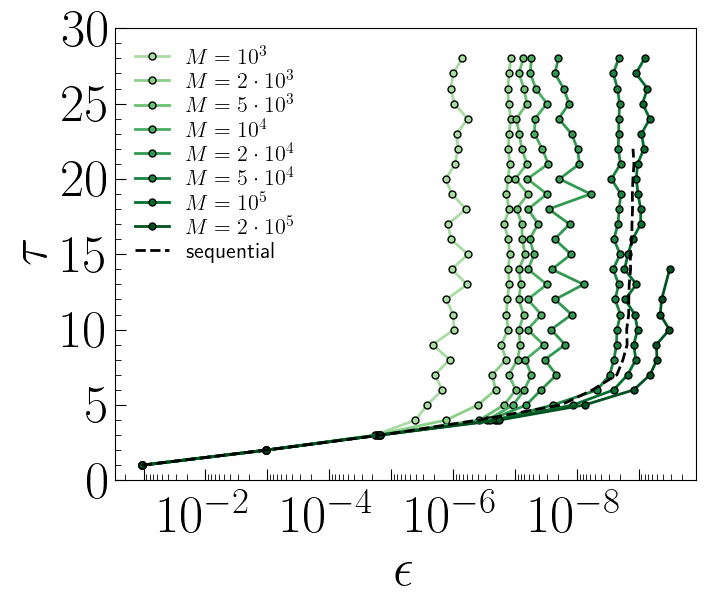

In [ ]:
# (4) corrmps xi=0.5, chi=20, N=100, parallel: tau vs eps after M iterations, sequential (chi20_long) dashed.
# Every depth ran at least 61999 iterations: curves complete up to M = 60000.
N = 100
Ms = [1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000, 200_000]
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
plot_iters(ax, it_corr05[it_corr05.N == N], Ms, plt.cm.Greens)
ax.plot(seq_corr05.err, seq_corr05.tau, 'k--', lw=2, label='sequential')
tau_eps_axes(ax)
ax.set_ylim(0, 30)
ax.legend(frameon=False, fontsize=14, loc='lower left', bbox_to_anchor=(0, 0.13), handlelength=1.2, labelspacing=0.2,
          ncol=2, columnspacing=0.8)                  # above the shallow depths

# inset: geometric mean over the saturated depths tau = 7..28 of the error after M iterations, for every M at which
# all of them are available (M <= 1e5); band: min-max over the depths. Dashed: power law eps = A M^-p.
dw = it_corr05[(it_corr05.N == N) & (it_corr05.tau >= 7)].dropna(subset=['err'])
ntau = dw.tau.nunique()
w = dw.groupby('M').err.agg(gm=lambda x: np.exp(np.mean(np.log(x))), lo='min', hi='max', n='size')
w = w[w.n == ntau]
pw, lA = np.polyfit(np.log(w.index), np.log(w.gm), 1)
print(f'(4) xi=0.5 saturated depths: eps = {np.exp(lA):.3g} M^{pw:.2f}  (M = {w.index.min()}..{w.index.max()}, {ntau} depths)')
ins = ax.inset_axes([0.16, 0.62, 0.36, 0.34])
ins.fill_between(w.index, w.lo, w.hi, color=plt.cm.Greens(0.5), alpha=0.3, lw=0)
ins.plot(w.index, w.gm, 'o', c=plt.cm.Greens(0.8), mec='k', mew=0.5, ms=4)
ins.plot(w.index, np.exp(lA) * w.index.values.astype(float) ** pw, 'k--', lw=1.2)
ins.text(0.95, 0.92, rf'$\bar\epsilon\propto M^{{{pw:.2f}}}$', transform=ins.transAxes, ha='right', va='top', fontsize=16)
ins.set_xscale('log'); ins.set_yscale('log')
ins.set_xlabel(r'$M$', fontsize=16, labelpad=-4); ins.set_ylabel(r'$\bar\epsilon$', fontsize=16, labelpad=2)
ins.tick_params(which='both', direction='in', labelsize=14)
ins.xaxis.set_minor_formatter(mpl.ticker.NullFormatter()); ins.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
plt.savefig(resultspath + 'corr_xi0.5_iters.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'corr_xi0.5_iters.png', bbox_inches='tight', dpi=300)

C:\Users\rikci\AppData\Local\Temp\ipykernel_14656\232565247.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False, fontsize=16, loc='lower right', handlelength=1.5, labelspacing=0.2)


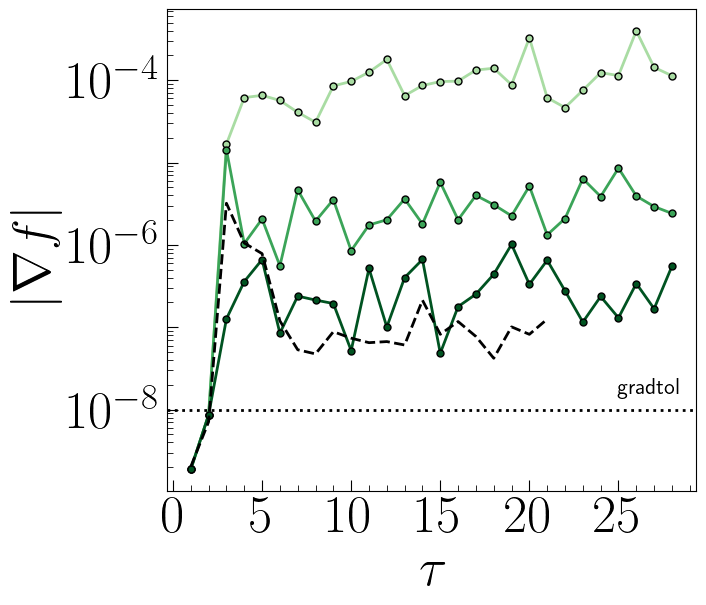

In [ ]:
# (4b) corrmps xi=0.5, chi=20, N=100, parallel: gradient norm of every depth after M iterations for M = 1e3, 1e4, 1e5
# (colours as for the same M in the tau vs eps figure above), dashed: final |grad| of each depth of the sequential
# run (chi20_long, N100_depths.csv).
N = 100
Ms_all = [1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000, 200_000]           # Ms of the tau vs eps figure
shade = dict(zip(Ms_all, np.linspace(0.35, 0.95, len(Ms_all))))                # shades of plot_iters
Ms = [1000, 10_000, 100_000]
d = it_corr05[it_corr05.N == N]
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
for M in Ms:
    dm = d[d.M == M].sort_values('tau').dropna(subset=['gradnorm'])
    ax.plot(dm.tau, dm.gradnorm, '-o', c=plt.cm.Greens(shade[M]), **MK, label=rf'$M={sci_label(M)[1:-1]}$')
sg = pd.read_csv(datapath + f'corrmps/chi20_long/xi0.5/N{N}_depths.csv')
sg = sg[sg.event == 'finished'].drop_duplicates('tau', keep='last').sort_values('tau')
ax.plot(sg.tau, sg.gradnorm, 'k--', lw=2, label='sequential')
ax.set_yscale('log')
ax.set_xlabel(r'$\tau$')
ax.set_ylabel(r'$|\nabla f|$')
ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(5))
ax.xaxis.set_minor_locator(mpl.ticker.MultipleLocator(1))
ax.yaxis.set_major_locator(mpl.ticker.LogLocator(base=10, numticks=100))
ax.yaxis.set_minor_locator(mpl.ticker.LogLocator(base=10, subs=np.arange(2, 10), numticks=100))
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_major_formatter(even_decades)
ax.tick_params(which='both', direction='in')
ax.tick_params(which='major', length=8)
ax.tick_params(which='minor', length=4)
ax.legend(frameon=False, fontsize=16, loc='lower right', handlelength=1.5, labelspacing=0.2)
plt.savefig(resultspath + 'corr_xi0.5_grad_iters.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'corr_xi0.5_grad_iters.png', bbox_inches='tight', dpi=300)

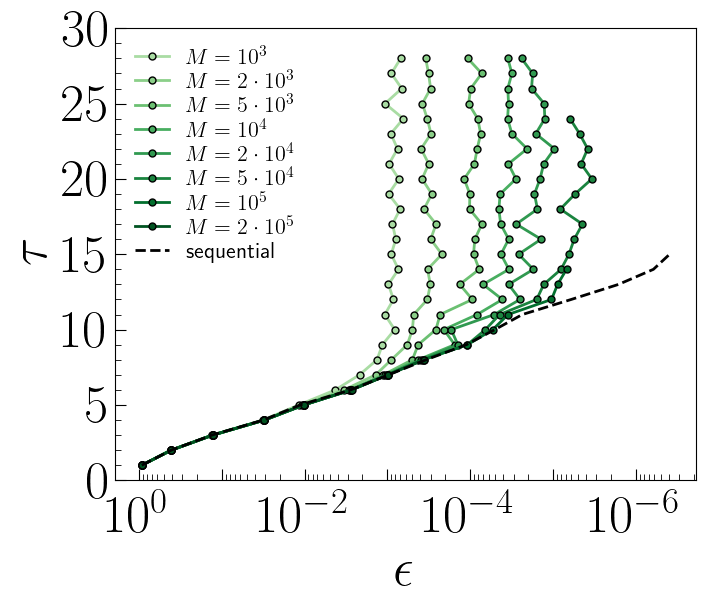

In [ ]:
# (4) corrmps xi=2.0, chi=20, N=100, parallel: tau vs eps after M iterations, sequential (chi20_long) dashed.
# Every depth ran at least 61999 iterations: curves complete up to M = 60000.
N = 100
Ms = [1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000, 200_000]
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
plot_iters(ax, it_corr2[it_corr2.N == N], Ms, plt.cm.Greens)
ax.plot(seq_corr2.err, seq_corr2.tau, 'k--', lw=2, label='sequential')
tau_eps_axes(ax)
ax.set_ylim(0, 30)
ax.legend(frameon=False, fontsize=16, loc='upper left', handlelength=1.5, labelspacing=0.2)
plt.savefig(resultspath + 'corr_xi2.0_iters.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'corr_xi2.0_iters.png', bbox_inches='tight', dpi=300)

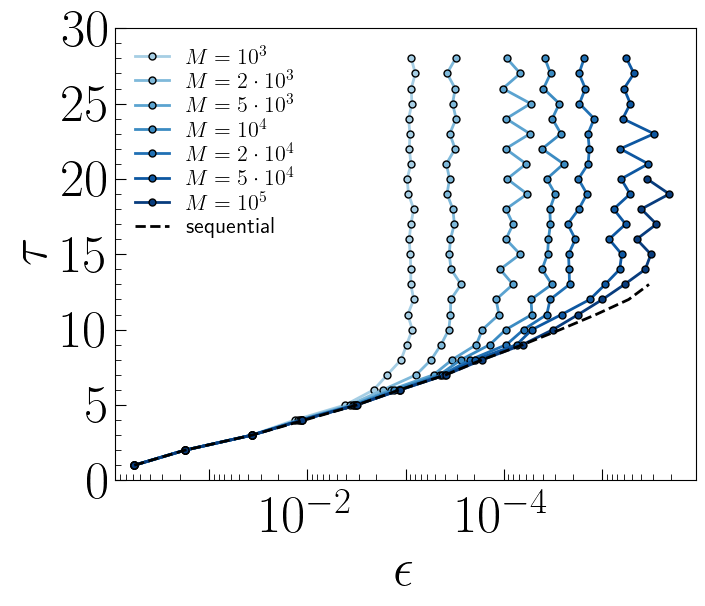

In [13]:
# (4) Ising g=0.75, chi=20, N=100, parallel (m5_long/parallel): tau vs eps after M iterations, sequential (m5_long) dashed.
# Every depth ran at least 60000 iterations: curves complete up to M = 50000; M = 100000 reaches tau <= 20.
N = 100
Ms = [1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000]
it_ising = pd.read_csv(datapath + 'ising/g0.75/m5_long/parallel/df_iters.csv')
seq_ising = pd.read_csv(datapath + 'ising/g0.75/m5_long/df.csv')
seq_ising = seq_ising[seq_ising.N == N].sort_values('tau')
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
plot_iters(ax, it_ising[it_ising.N == N], Ms, plt.cm.Blues)
ax.plot(seq_ising.err, seq_ising.tau, 'k--', lw=2, label='sequential')
tau_eps_axes(ax)
ax.set_xlim(left=0.9)                                # eps(tau=1) = 0.58; 10^0 just outside, off the y labels
ax.set_ylim(0, 30)
ax.legend(frameon=False, fontsize=16, loc='upper left', handlelength=1.5, labelspacing=0.2)
plt.savefig(resultspath + 'ising_g0.75_iters.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'ising_g0.75_iters.png', bbox_inches='tight', dpi=300)

In [ ]:
# (4) XXZ Jz = 10, 20, 50, chi=20, N=100, parallel: tau vs eps after M iterations (no sequential runs for these).
# df_iters.csv extracted with extract_data_iters(..., include_checkpoints = true): depths still running give NaN past
# their history; converged ones (all of Jz=50, stopped by gradtol before M = 1e5) repeat their final error, so Jz=50
# stops at M = 1e5. Complete up to M = 5e4 (Jz=10; 1e5 reaches tau <= 21) and 1e5 (Jz=20; 2e5 reaches tau <= 17).
N = 100
for Jz, Ms in [(10, [1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000, 200_000]),
               (20, [1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000, 200_000]),
               (50, [1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000])]:
    it_jz = pd.read_csv(datapath + f'xxz/Jz{Jz}/chi20/parallel/df_iters.csv')
    fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
    plot_iters(ax, it_jz[it_jz.N == N], Ms, plt.cm.Oranges)
    tau_eps_axes(ax)
    ax.set_ylim(0, 30)
    if Jz == 20:
        ax.set_xlim(left=0.1)                            # eps(tau=1) = 0.02: keeps 10^-2 off the y labels
    ax.legend(frameon=False, fontsize=16, loc='upper left', handlelength=1.5, labelspacing=0.2,
              title=rf'$J_z={Jz}$', title_fontsize=20, alignment='left')
    plt.savefig(resultspath + f'xxz_Jz{Jz}_iters.pdf', bbox_inches='tight')
    plt.savefig(resultspath + f'xxz_Jz{Jz}_iters.png', bbox_inches='tight', dpi=300)


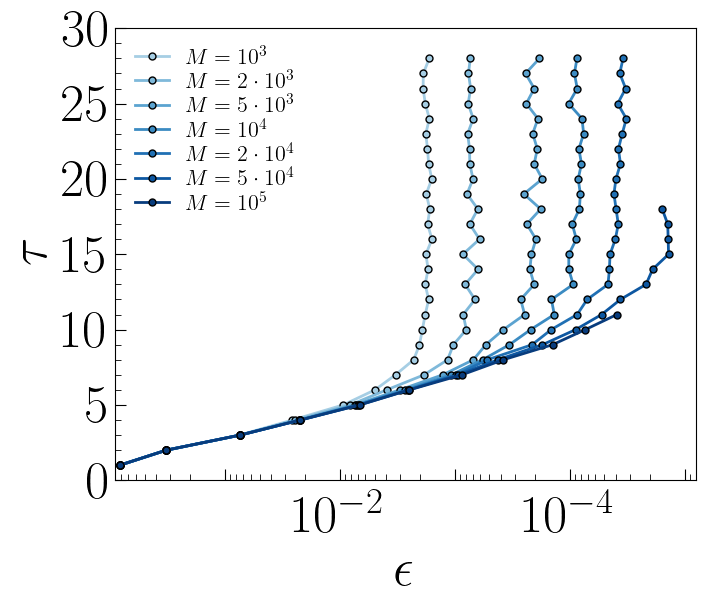

In [14]:
# (4) Ising g=0.75, chi=20, N=100, parallel (m5_long/parallel): tau vs eps after M iterations, sequential (m5_long) dashed.
# Every depth ran at least 60000 iterations: curves complete up to M = 50000; M = 100000 reaches tau <= 20.
N = 200
Ms = [1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000]
it_ising = pd.read_csv(datapath + 'ising/g0.75/m5_long/parallel/df_iters.csv')
seq_ising = pd.read_csv(datapath + 'ising/g0.75/m5_long/df.csv')
seq_ising = seq_ising[seq_ising.N == N].sort_values('tau')
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
plot_iters(ax, it_ising[it_ising.N == N], Ms, plt.cm.Blues)
#ax.plot(seq_ising.err, seq_ising.tau, 'k--', lw=2, label='sequential')
tau_eps_axes(ax)
ax.set_xlim(left=0.9)                                # eps(tau=1) = 0.58; 10^0 just outside, off the y labels
ax.set_ylim(0, 30)
ax.legend(frameon=False, fontsize=16, loc='upper left', handlelength=1.5, labelspacing=0.2)
plt.savefig(resultspath + 'ising_N200_g0.75_iters.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'ising_N200_g0.75_iters.png', bbox_inches='tight', dpi=300)

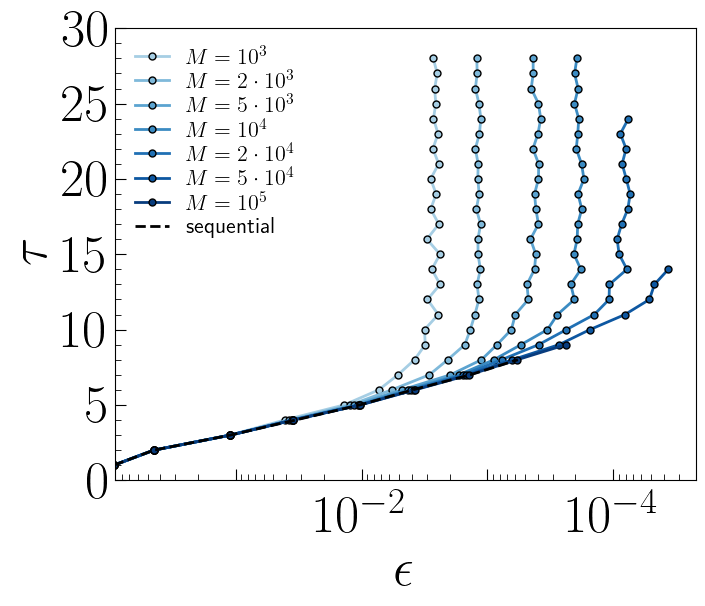

In [15]:
# (4) Ising g=0.75, chi=20, N=100, parallel (m5_long/parallel): tau vs eps after M iterations, sequential (m5_long) dashed.
# Every depth ran at least 60000 iterations: curves complete up to M = 50000; M = 100000 reaches tau <= 20.
N = 300
Ms = [1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000]
it_ising = pd.read_csv(datapath + 'ising/g0.75/m5_long/parallel/df_iters.csv')
seq_ising = pd.read_csv(datapath + 'ising/g0.75/m5_long/df.csv')
seq_ising = seq_ising[seq_ising.N == N].sort_values('tau')
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
plot_iters(ax, it_ising[it_ising.N == N], Ms, plt.cm.Blues)
ax.plot(seq_ising.err, seq_ising.tau, 'k--', lw=2, label='sequential')
tau_eps_axes(ax)
ax.set_xlim(left=0.9)                                # eps(tau=1) = 0.58; 10^0 just outside, off the y labels
ax.set_ylim(0, 30)
ax.legend(frameon=False, fontsize=16, loc='upper left', handlelength=1.5, labelspacing=0.2)
plt.savefig(resultspath + 'ising_N300_g0.75_iters.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'ising_N300_g0.75_iters.png', bbox_inches='tight', dpi=300)

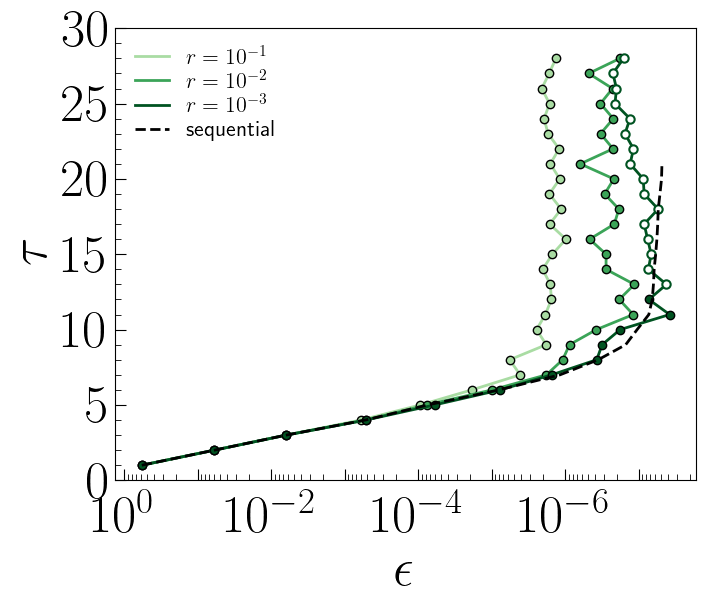

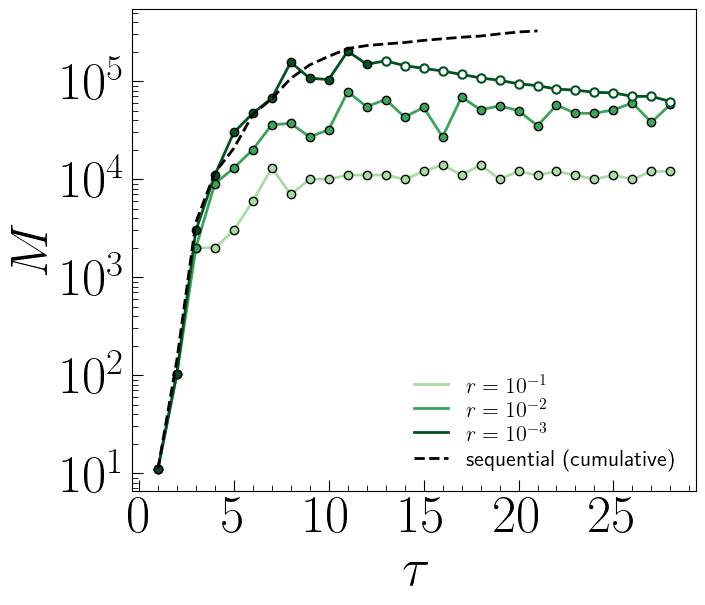

In [ ]:
# (5a) corrmps xi=1, N=100: tau vs eps at the err_reltol stops, sequential run dashed.
# Hollow: the depth had not met the criterion by the end of its history (error there, a lower bound on M).
reltols = [1e-1, 1e-2, 1e-3]
d = st_corr[st_corr.N == N]
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
plot_stops(ax, d, 'err_stop', 'tau', reltols, plt.cm.Greens)
ax.plot(seq_corr.err, seq_corr.tau, 'k--', lw=2, label='sequential')
tau_eps_axes(ax)
ax.set_ylim(0, 30)
ax.legend(frameon=False, fontsize=16, loc='upper left', handlelength=1.5, labelspacing=0.2)
plt.savefig(resultspath + 'corr_xi1_reltol_err.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'corr_xi1_reltol_err.png', bbox_inches='tight', dpi=300)

# (5b) iterations at the stops vs the cumulative iterations of the sequential run (depth tau of a sequential
# run costs the iterations of all depths <= tau)
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
plot_stops(ax, d, 'tau', 'stop_iter', reltols, plt.cm.Greens)
ax.plot(seq_corr.tau, seq_corr.niter_cum, 'k--', lw=2, label='sequential (cumulative)')
iter_tau_axes(ax)
ax.legend(frameon=False, fontsize=16, loc='lower right', handlelength=1.5, labelspacing=0.2)
plt.savefig(resultspath + 'corr_xi1_reltol_iters.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'corr_xi1_reltol_iters.png', bbox_inches='tight', dpi=300)

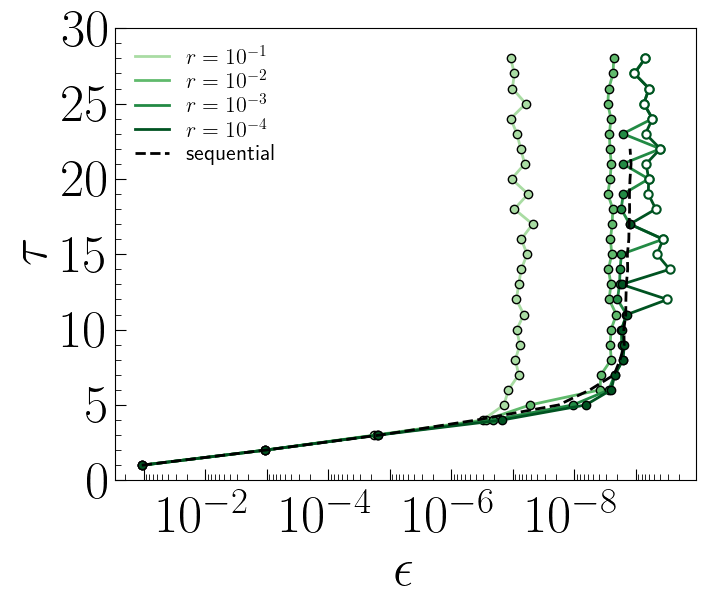

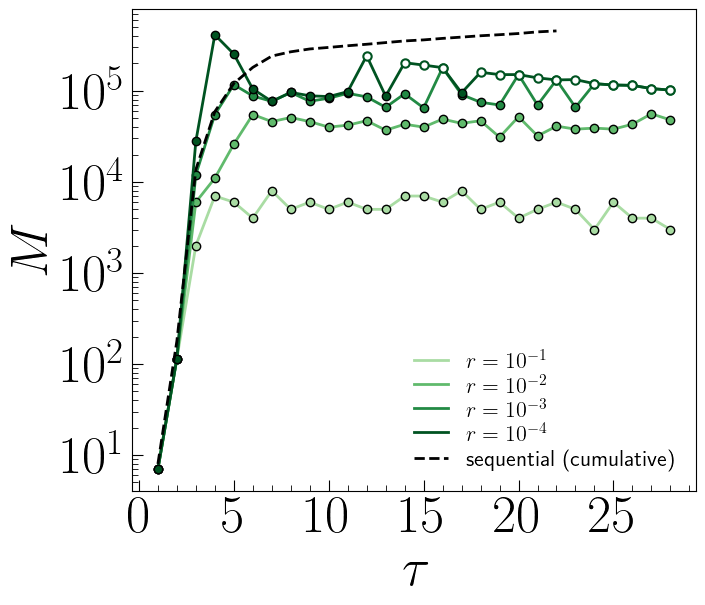

In [ ]:
# (5a) corrmps xi=0.5, N=100: tau vs eps at the err_reltol stops, sequential run dashed.
# Hollow: the depth had not met the criterion by the end of its history (error there, a lower bound on M).
N = 100
reltols = [1e-1, 1e-2, 1e-3, 1e-4]
d = st_corr05[st_corr.N == N]
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
plot_stops(ax, d, 'err_stop', 'tau', reltols, plt.cm.Greens)
ax.plot(seq_corr05.err, seq_corr05.tau, 'k--', lw=2, label='sequential')
tau_eps_axes(ax)
ax.set_ylim(0, 30)
ax.legend(frameon=False, fontsize=16, loc='upper left', handlelength=1.5, labelspacing=0.2)
plt.savefig(resultspath + 'corr_xi0.5_reltol_err.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'corr_xi0.5_reltol_err.png', bbox_inches='tight', dpi=300)

# (5b) iterations at the stops vs the cumulative iterations of the sequential run (depth tau of a sequential
# run costs the iterations of all depths <= tau)
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
plot_stops(ax, d, 'tau', 'stop_iter', reltols, plt.cm.Greens)
ax.plot(seq_corr05.tau, seq_corr05.niter_cum, 'k--', lw=2, label='sequential (cumulative)')
iter_tau_axes(ax)
ax.legend(frameon=False, fontsize=16, loc='lower right', handlelength=1.5, labelspacing=0.2)
plt.savefig(resultspath + 'corr_xi0.5_reltol_iters.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'corr_xi0.5_reltol_iters.png', bbox_inches='tight', dpi=300)

(6) xi=0.5: M = 0.0651 eps^-0.689  (M = 1000..100000, tau >= 7)
(6) xi=1: M = 0.92 eps^-0.714  (M = 1000..50000, tau >= 11)
(6) xi=2: M = 4.66 eps^-0.754  (M = 1000..20000, tau >= 12)


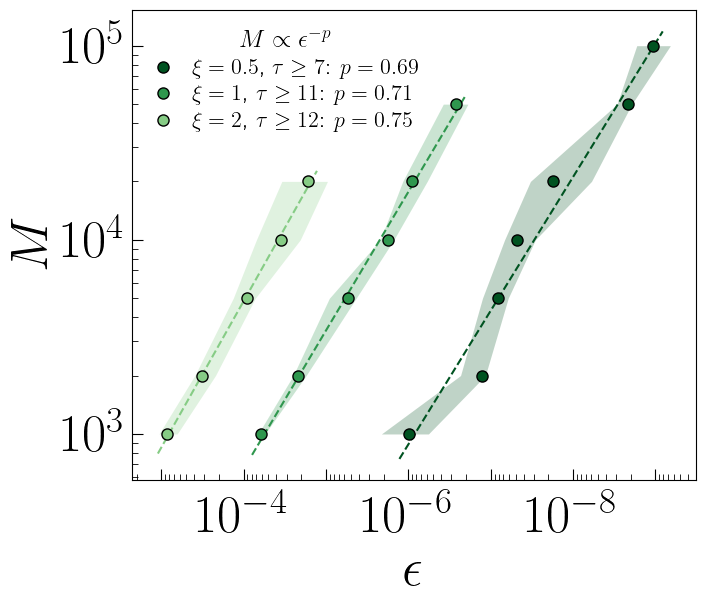

In [ ]:
# (6) corrmps xi = 0.5, 1, 2, chi=20, N=100, parallel: iterations M vs the error eps of the saturated depths ("wall").
# For every xi: median over the depths tau >= tau0 (where eps no longer depends on tau) of the error after M iterations,
# only at the M where all those depths are available; band: min-max over the depths.
# Dashed: power law M = B eps^-p fitted on the medians (log M vs log eps), to read off the iterations needed for eps.
N = 100
Ms = [1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000, 200_000]
walls = [(0.5, it_corr05, 7, plt.cm.Greens(0.95)),
         (1, it_corr, 11, plt.cm.Greens(0.7)),
         (2, it_corr2, 12, plt.cm.Greens(0.45))]
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
for xi, it, tau0, c in walls:
    dw = it[(it.N == N) & (it.tau >= tau0) & it.M.isin(Ms)].dropna(subset=['err'])
    w = dw.groupby('M').err.agg(med='median', lo='min', hi='max', n='size')
    w = w[w.n == dw.tau.nunique()]
    q, lB = np.polyfit(np.log(w.med), np.log(w.index), 1)
    print(f'(6) xi={xi}: M = {np.exp(lB):.3g} eps^{q:.3f}  (M = {w.index.min()}..{w.index.max()}, tau >= {tau0})')
    ax.fill_betweenx(w.index, w.lo, w.hi, color=c, alpha=0.25, lw=0)
    ax.plot(w.med, w.index, 'o', c=c, mec='k', mew=1, ms=MK['ms'] + 3,
            label=rf'$\xi={xi}$, $\tau\geq{tau0}$:  $p={-q:.2f}$')
    eps = np.geomspace(w.med.max() * 1.3, w.med.min() / 1.3, 50)       # just past the first and last median
    ax.plot(eps, np.exp(lB) * eps ** q, '--', c=c, lw=1.5, zorder=1)
ax.set_xscale('log'); ax.set_yscale('log')
ax.invert_xaxis()
ax.set_xlabel(r'$\epsilon$')
ax.set_ylabel(r'$M$')
log_ticks(ax)
ax.xaxis.set_major_formatter(even_decades)
ax.tick_params(axis='x', which='major', pad=12)
ax.legend(frameon=False, fontsize=16, loc='upper left', handlelength=1, labelspacing=0.3,
          title=r'$M\propto\epsilon^{-p}$', title_fontsize=18)
plt.savefig(resultspath + 'corr_wall_M_vs_eps.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'corr_wall_M_vs_eps.png', bbox_inches='tight', dpi=300)


(6b) ising N=100: M = 2.33 eps^-0.840  (M = 1000..100000, tau = 13..18)
(6b) ising N=200: M = 5.02 eps^-0.823  (M = 1000..50000, tau = 13..18)
(6b) ising N=300: M = 5.33 eps^-0.880  (M = 1000..30000, tau = 13..18)
(6b) ising collapse: M = 0.0616 (eps/N)^-0.829
(6b) xxz N=100: M = 0.25 eps^-1.114  (M = 1000..50000, tau = 15..20)
(6b) xxz N=200: M = 0.888 eps^-1.061  (M = 1000..20000, tau = 15..20)
(6b) xxz N=300: M = 8.61 eps^-0.757  (M = 1000..10000, tau = 15..20)
(6b) xxz collapse: M = 0.00479 (eps/N)^-1.021


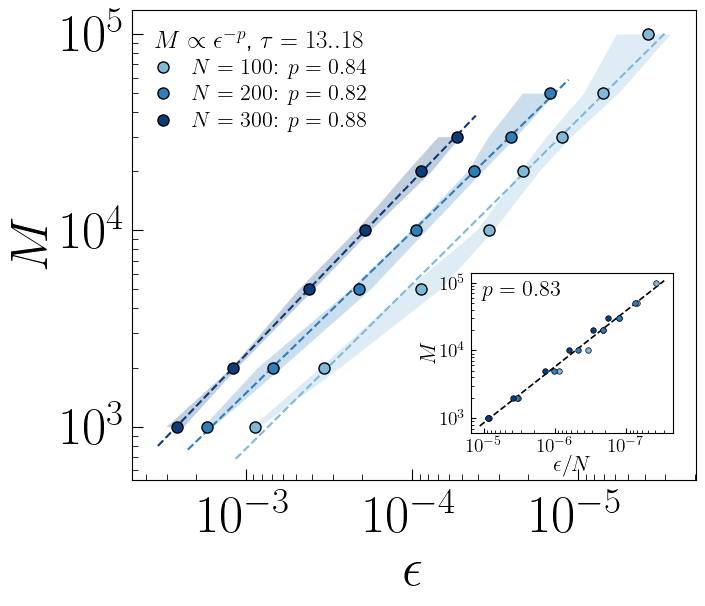

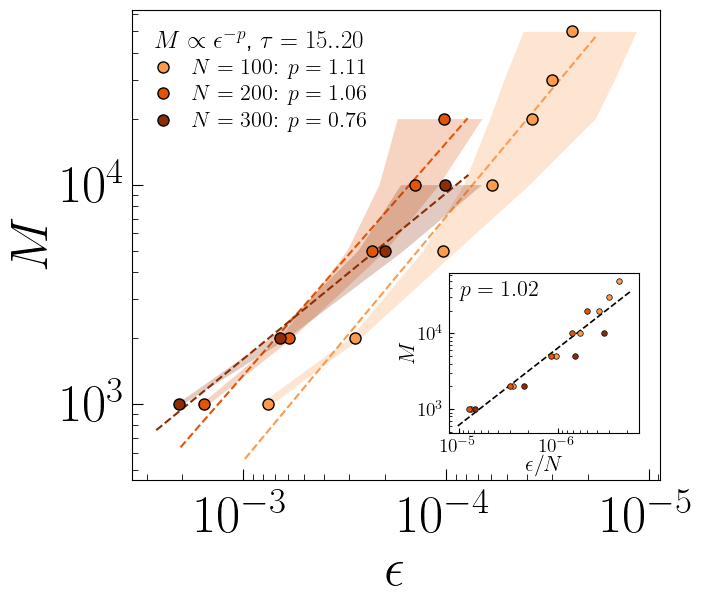

In [11]:
# (6b) Ising g=0.75 (m5_long/parallel) and XXZ Jz=2.5 (chi36/parallel), N = 100, 200, 300: iterations M vs the error eps
# of the deep depths, as in (6). Median over a fixed window of depths tau0..tau1 of the error after M iterations, only at
# the M where all of them are available; band: min-max over the window. Dashed: M = B eps^-p fitted on the medians.
# Inset (lower right): the same medians against the error per site eps/N, collapsing the three N; dashed: joint fit.
# Ising: flat in tau from tau ~ 13. XXZ: still slowly improving with tau at large M (tau ~ chi_trunc^2), so its band is
# partly the depth dependence and its largest-M points are partly depth-limited.
Ms = [1000, 2000, 5000, 10_000, 20_000, 30_000, 50_000, 100_000]
it_ising = pd.read_csv(datapath + 'ising/g0.75/m5_long/parallel/df_iters.csv')
fams_w = [('ising', it_ising, (13, 18), plt.cm.Blues), ('xxz', it_xxz[36], (15, 20), plt.cm.Oranges)]
Ns = [100, 200, 300]
for name, it, (tau0, tau1), cmap in fams_w:
    fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
    ins = ax.inset_axes([0.6, 0.1, 0.36, 0.34])
    allw = []
    for N, s in zip(Ns, [0.45, 0.7, 0.95]):
        c = cmap(s)
        dw = it[(it.N == N) & it.tau.between(tau0, tau1) & it.M.isin(Ms)].dropna(subset=['err'])
        w = dw.groupby('M').err.agg(med='median', lo='min', hi='max', n='size')
        w = w[w.n == tau1 - tau0 + 1]
        q, lB = np.polyfit(np.log(w.med), np.log(w.index), 1)
        print(f'(6b) {name} N={N}: M = {np.exp(lB):.3g} eps^{q:.3f}  (M = {w.index.min()}..{w.index.max()}, tau = {tau0}..{tau1})')
        ax.fill_betweenx(w.index, w.lo, w.hi, color=c, alpha=0.25, lw=0)
        ax.plot(w.med, w.index, 'o', c=c, mec='k', mew=1, ms=MK['ms'] + 3, label=rf'$N={N}$:  $p={-q:.2f}$')
        eps = np.geomspace(w.med.max() * 1.3, w.med.min() / 1.3, 50)       # just past the first and last median
        ax.plot(eps, np.exp(lB) * eps ** q, '--', c=c, lw=1.5, zorder=1)
        ins.plot(w.med / N, w.index, 'o', c=c, mec='k', mew=0.5, ms=4)
        allw.append(pd.DataFrame({'x': w.med.values / N, 'M': w.index.values}))
    allw = pd.concat(allw)
    qc, lC = np.polyfit(np.log(allw.x), np.log(allw.M), 1)
    print(f'(6b) {name} collapse: M = {np.exp(lC):.3g} (eps/N)^{qc:.3f}')
    x = np.geomspace(allw.x.max() * 1.3, allw.x.min() / 1.3, 50)
    ins.plot(x, np.exp(lC) * x ** qc, 'k--', lw=1.2, zorder=1)
    ins.text(0.05, 0.95, rf'$p={-qc:.2f}$', transform=ins.transAxes, ha='left', va='top', fontsize=16)
    ins.set_xscale('log'); ins.set_yscale('log')
    ins.invert_xaxis()
    ins.set_xlabel(r'$\epsilon/N$', fontsize=16, labelpad=0); ins.set_ylabel(r'$M$', fontsize=16, labelpad=0)
    ins.tick_params(which='both', direction='in', labelsize=14)
    ins.xaxis.set_minor_formatter(mpl.ticker.NullFormatter()); ins.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.invert_xaxis()
    ax.set_xlabel(r'$\epsilon$')
    ax.set_ylabel(r'$M$')
    log_ticks(ax)
    ax.xaxis.set_major_formatter(mpl.ticker.LogFormatterMathtext())       # only ~2 decades: label all of them
    ax.tick_params(axis='x', which='major', pad=12)
    ax.legend(frameon=False, fontsize=16, loc='upper left', handlelength=1, labelspacing=0.3,
              title=rf'$M\propto\epsilon^{{-p}}$, $\tau={tau0}..{tau1}$', title_fontsize=18)
    plt.savefig(resultspath + f'{name}_wall_M_vs_eps.pdf', bbox_inches='tight')
    plt.savefig(resultspath + f'{name}_wall_M_vs_eps.png', bbox_inches='tight', dpi=300)


In [ ]:
# tau vs chi_trunc(N/eps)^2: the depth needed for an error eps grows like the square of the bond dimension
# that plain truncation of the target needs for the same error (parameter counting: a depth-tau brickwork has
# 15 N tau / 2 parameters, an MPS of bond dimension chi ~ N chi^2).
# chi_trunc(N/eps): fit ln chi = b sqrt(ln(N/eps)) + c to the truncation errors of the ground states
# (truncation_eps.csv: eps = 1 - |<psi|psi_chi>| after an SVD truncation to chi, all N together).
# Filled: converged depths of the parallel runs (fit tau = a chi^2 on tau >= 2); hollow: final error of the
# depths that did not converge (the converged error is lower, so these points can only move right).
fams = {
    'XXZ': dict(trunc=datapath + 'xxz/Jz2.5/truncation_eps.csv', chis=(2, 16),     # ground states have chi = 24
                runs=datapath + 'xxz/Jz2.5/sweeps/chi36/parallel/df_iters.csv', cmap=plt.cm.Oranges,
                label=r'XXZ'),
    'Ising': dict(trunc=datapath + 'ising/g0.75/m5_long/truncation_eps.csv', chis=(2, 6),  # ground states have chi = 9
                  runs=datapath + 'ising/g0.75/m5_long/parallel/df_iters.csv', cmap=plt.cm.Blues,
                  label=r'Ising'),
}
Ns = [100, 200, 300]
shade = dict(zip(Ns, [0.45, 0.7, 0.95]))
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
for name, f in fams.items():
    t = pd.read_csv(f['trunc'])
    t = t[(t.chi >= f['chis'][0]) & (t.chi <= f['chis'][1])]
    bt, ct = np.polyfit(np.sqrt(np.log(t.N / t.eps)), np.log(t.chi), 1)
    chi_trunc = lambda N, eps: np.exp(bt * np.sqrt(np.log(N / eps)) + ct)
    it = pd.read_csv(f['runs'])
    fin = it.dropna(subset=['err']).sort_values('M').groupby(['N', 'tau']).last().reset_index()   # last M reached
    fin['chi2'] = chi_trunc(fin.N, fin.err) ** 2
    conv = fin[fin.converged & (fin.tau >= 2)]
    a = np.exp(np.mean(np.log(conv.tau / conv.chi2)))                                  # tau = a chi^2
    p, _ = np.polyfit(np.log(conv.chi2), np.log(conv.tau), 1)
    print(f'{name}: ln chi_trunc = {bt:.3f} sqrt(ln(N/eps)) {ct:+.3f};  tau = {a:.3f} chi^2 '
          f'({len(conv)} converged depths, free exponent tau ~ chi^{2*p:.2f})')
    for N in Ns:
        c = f['cmap'](shade[N])
        g = fin[(fin.N == N) & (fin.tau >= 1)].sort_values('tau')
        gc, gu = g[g.converged & (g.tau >= 2)], g[~g.converged]
        ax.plot(gc.chi2, gc.tau, 'o', c=c, mec='k', mew=1, ms=8, label=f['label'] + rf' $N={N}$')
        ax.plot(gu.chi2, gu.tau, 'o', mfc='none', mec=c, mew=1.5, ms=6)
    xs = np.linspace(0, conv.chi2.max() * 1.3, 50)
    ax.plot(xs, a * xs, '--', c=f['cmap'](0.8), lw=2, zorder=0, label=rf'$\tau={a:.2f}\,\chi^2$')
ax.set_xlabel(r'$\chi_{\rm trunc}(N/\epsilon)^2$')
ax.set_ylabel(r'$\tau$')
ax.set_xlim(0, 30); ax.set_ylim(0, 16)          # deeper unconverged depths only show the iteration wall
ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(10)); ax.xaxis.set_minor_locator(mpl.ticker.MultipleLocator(2))
ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(5)); ax.yaxis.set_minor_locator(mpl.ticker.MultipleLocator(1))
ax.tick_params(which='both', direction='in'); ax.tick_params(which='major', length=8); ax.tick_params(which='minor', length=4)
ax.legend(frameon=False, fontsize=14, loc='lower right', ncol=2, handlelength=1.2, labelspacing=0.2, columnspacing=0.8)
plt.savefig(resultspath + 'tau_vs_chi2.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'tau_vs_chi2.png', bbox_inches='tight', dpi=300)

In [ ]:
# (1b) XXZ Jz=2.5, chi=36, parallel: tau vs eps after M iterations, with the bond dimension chi_trunc(eps) that an MPS
# needs to reach the same error (heuristic parameter-counting bound tau >= A chi_trunc^2).
# chi_trunc(eps) = smallest chi whose optimal truncation has error <= eps. truncation_var_N{N}.csv: variational
# compression of the ground state (compress of rrules.jl, chi = 23 -> 2, each warm-started from the chi+1 optimum).
# A_fit: the largest A for which no data point (any M) lies below A chi_trunc^2 (set by tau = 1, a single layer, which
# reaches chi = 2: A = 1/4; without tau = 1 it would be 0.28-0.32).
# Rigorous: a depth-tau brickwork state has bond dimension <= 2^tau, so tau >= log2 chi_trunc(eps).
# Theory: corner-transfer-matrix spectrum of the infinite XXZ chain (Peschel, Kaulke, Legeza 1999):
# rho ~ exp(-sum_l 2 l gamma n_l), n_l in {0, 1}, cosh(gamma) = Delta; the error of an SVD truncation of all bonds is
# eps ~ (N/2) w(chi), w = discarded weight of one cut. The ground states have a staggered pinning field h_s = 0.05,
# which the CTM formula does not include.
def ctm_spectrum(Delta, nmax=60, kmax=5000):
    g = np.arccosh(Delta)
    q = np.zeros(nmax + 1); q[0] = 1                          # q(n): partitions of n into distinct parts
    for l in range(1, nmax + 1):
        for n in range(nmax, l - 1, -1): q[n] += q[n - l]
    lev = np.repeat(np.arange(nmax + 1), np.minimum(q, kmax).astype(int))[:kmax]
    return np.exp(-2 * g * lev) / np.sum(q * np.exp(-2 * g * np.arange(nmax + 1)))

def chi_needed(eps, tr):
    """smallest chi with truncation error <= eps (tr: DataFrame chi, eps)"""
    tr = tr.sort_values('chi')
    return np.array([tr.chi[tr.eps <= e].min() if (tr.eps <= e).any() else np.nan for e in np.atleast_1d(eps)])

def stairs(ax, tr, A, emin, **kw):
    """A chi_needed(eps)^2 as a staircase: chi is needed on (eps(chi), eps(chi-1)]"""
    tr = tr.sort_values('chi')
    e = np.r_[1.0, tr.eps.values]; c = np.r_[tr.chi.values, tr.chi.values[-1]]
    keep = e >= emin
    x = np.r_[e[keep], emin]; y = A * np.r_[c[keep], c[keep][-1]] ** 2
    ax.step(x, y, where='post', **kw)

lam_ctm = ctm_spectrum(2.5)
w_ctm = 1 - np.cumsum(lam_ctm)
Ms = [1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000]
for N in (100, 200, 300):
    tv = pd.read_csv(datapath + f'xxz/Jz2.5/truncation_var_N{N}.csv')
    tv = pd.concat([pd.DataFrame(dict(chi=[1], eps_var=[np.nan])), tv])              # chi = 1 from SVD below
    ts = pd.read_csv(datapath + 'xxz/Jz2.5/truncation_eps.csv'); ts = ts[ts.N == N].set_index('chi').eps
    tv['eps'] = np.where(tv.chi == 1, ts[1], tv.eps_var)
    tr = tv[['chi', 'eps']]
    th = pd.DataFrame(dict(chi=np.arange(1, 40), eps=N * w_ctm[:39] / 2))
    d = it_xxz[36][(it_xxz[36].N == N) & it_xxz[36].M.isin(Ms)].dropna(subset=['err'])
    cn = chi_needed(d.err.values, tr)
    A_fit = np.nanmin(d.tau.values / cn ** 2)
    b = np.nanargmin(d.tau.values / cn ** 2)
    print(f'N={N}: A_fit = {A_fit:.3f} (binding point tau={d.tau.values[b]}, M={d.M.values[b]}, eps={d.err.values[b]:.2e}, '
          f'chi_trunc={cn[b]:.0f});  optimal/SVD error ratio at chi=2..8: '
          + ' '.join(f'{r:.4f}' for r in tv.set_index('chi').eps_var.sort_index().loc[2:8].values / ts.sort_index().loc[2:8].values))
    fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
    plot_iters(ax, d, Ms, plt.cm.Oranges)
    emin = d.err.min() / 3
    stairs(ax, tr, A_fit, emin, c='k', lw=2.5, zorder=6, label=rf'${A_fit:.2f}\,\chi_{{\rm trunc}}(\epsilon)^2$')
    stairs(ax, th, A_fit, emin, c='tab:purple', lw=1.8, ls='--', zorder=5, label=rf'${A_fit:.2f}\,\chi_{{\rm CTM}}(\epsilon)^2$')
    tl = tr.copy(); tl['chi'] = np.log2(tl.chi)          # tau >= log2 chi: plotted with A=1 on chi -> sqrt(log2 chi)
    tl['chi'] = np.sqrt(tl.chi)
    stairs(ax, tl, 1.0, emin, c='k', lw=1.5, ls=':', zorder=5, label=r'$\log_2\chi_{\rm trunc}(\epsilon)$')
    tau_eps_axes(ax)
    ax.set_xlim(left=1.0)
    h, l = ax.get_legend_handles_labels()
    ax.add_artist(ax.legend(h[:len(Ms)], l[:len(Ms)], frameon=False, fontsize=13, loc='upper left',
                            handlelength=1.5, labelspacing=0.15))
    ax.legend(h[len(Ms):], l[len(Ms):], frameon=False, fontsize=13, loc='upper left', bbox_to_anchor=(0, 0.6),
              handlelength=1.8, labelspacing=0.15)
    ax.set_title(rf'$N={N}$', fontsize=18)
    plt.savefig(resultspath + f'xxz_chi36_bound_N{N}.pdf', bbox_inches='tight')
    plt.savefig(resultspath + f'xxz_chi36_bound_N{N}.png', bbox_inches='tight', dpi=300)

In [ ]:
# tau vs chi(N/eps)^2 for the XXZ chi=36 parallel runs, with a smooth chi(N/eps):
# (a) theory: CTM spectrum (ctm_spectrum above). Its complete levels give exact corners (chi_k, w_k), chi_k = 1, 2, 3,
#     5, 7, 10, 14, ... states up to level k, w_k = weight above it; a monotone (PCHIP) interpolation of ln chi vs
#     ln(1/w) through the corners, with eps = (N/2) w, gives a smooth chi_CTM(N/eps).
# (b) the optimal truncations of the ground states (truncation_var_N{N}.csv), PCHIP of ln chi vs ln(N/eps) through
#     every integer chi.
# Last M reached for each (N, tau): filled = converged, hollow = not converged (their converged error would be lower,
# i.e. further right). Dashed: tau = a chi^2 fitted on the converged depths tau >= 2.
from scipy.interpolate import PchipInterpolator
def ctm_corners(Delta, nmax=80, kmax=12):
    g = np.arccosh(Delta)
    q = np.zeros(nmax + 1); q[0] = 1
    for l in range(1, nmax + 1):
        for n in range(nmax, l - 1, -1): q[n] += q[n - l]
    p = q * np.exp(-2 * g * np.arange(nmax + 1)); p /= p.sum()
    return np.cumsum(q)[:kmax], (1 - np.cumsum(p))[:kmax]
chi_k, w_k = ctm_corners(2.5)
f_ctm = PchipInterpolator(np.log(1 / w_k), np.log(chi_k))
chi_ctm = lambda N, eps: np.exp(f_ctm(np.log(N / (2 * eps))))
ts_all = pd.read_csv(datapath + 'xxz/Jz2.5/truncation_eps.csv')
def chi_opt_fun(N):
    t = pd.read_csv(datapath + f'xxz/Jz2.5/truncation_var_N{N}.csv').sort_values('chi')
    e1 = ts_all[(ts_all.N == N) & (ts_all.chi == 1)].eps.iloc[0]                  # chi = 1: product state (SVD)
    f = PchipInterpolator(np.log(N / np.r_[e1, t.eps_var.values]), np.log(np.r_[1, t.chi.values]))
    return lambda eps: np.exp(f(np.log(N / eps)))
chi_opt = {N: chi_opt_fun(N) for N in (100, 200, 300)}

fin = it_xxz[36].dropna(subset=['err']).sort_values('M').groupby(['N', 'tau']).last().reset_index()
fin['chi_ctm'] = chi_ctm(fin.N, fin.err)
fin['chi_opt'] = [chi_opt[N](e) for N, e in zip(fin.N, fin.err)]
Ns = [100, 200, 300]
shade = dict(zip(Ns, [0.45, 0.7, 0.95]))
fig, axs = plt.subplots(1, 2, figsize=(16, 7), layout='tight', sharey=True)
for ax, col, lab in zip(axs, ('chi_ctm', 'chi_opt'), (r'\chi_{\rm CTM}', r'\chi_{\rm trunc}')):
    conv = fin[fin.converged & (fin.tau >= 2)]
    x2 = conv[col] ** 2
    a = np.sum(conv.tau * x2) / np.sum(x2 ** 2)
    p, _ = np.polyfit(np.log(x2), np.log(conv.tau), 1)
    print(f'{col}: tau = {a:.3f} chi^2 (rms {np.sqrt(np.mean((conv.tau - a * x2) ** 2)):.2f}), free exponent tau ~ chi^{2*p:.2f}')
    for N in Ns:
        g = fin[(fin.N == N) & (fin.tau >= 1)].sort_values('tau')
        gc, gu = g[g.converged], g[~g.converged]
        c = plt.cm.Oranges(shade[N])
        ax.plot(gc[col] ** 2, gc.tau, 'o', c=c, mec='k', mew=1, ms=8, label=rf'$N={N}$')
        ax.plot(gu[col] ** 2, gu.tau, 'o', mfc='none', mec=c, mew=1.5, ms=7)
    xs = np.linspace(0, 40, 50)
    ax.plot(xs, a * xs, 'k--', lw=1.5, zorder=0, label=rf'$\tau={a:.2f}\,{lab}^2$')
    ax.set_xlabel(rf'${lab}(N/\epsilon)^2$')
    ax.set_xlim(0, 36); ax.set_ylim(0, 20)
    ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(10)); ax.xaxis.set_minor_locator(mpl.ticker.MultipleLocator(2))
    ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(5)); ax.yaxis.set_minor_locator(mpl.ticker.MultipleLocator(1))
    ax.tick_params(which='both', direction='in'); ax.tick_params(which='major', length=8); ax.tick_params(which='minor', length=4)
    ax.legend(frameon=False, fontsize=14, loc='lower right', handlelength=1.2, labelspacing=0.2)
axs[0].set_ylabel(r'$\tau$')
for ax, l in zip(axs, ('(a)', '(b)')):
    ax.text(0.05, 0.92, l, transform=ax.transAxes)
plt.savefig(resultspath + 'xxz_chi36_tau_vs_chi2_smooth.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'xxz_chi36_tau_vs_chi2_smooth.png', bbox_inches='tight', dpi=300)

In [ ]:
# (7) Check of the truncated errors. The final circuit of every depth of every run used in these figures, recontracted
# on |0...0> with maximal intermediate bond dimension chi (the maxrank of the run), 2 chi and 4 chi
# (verify_chi.jl -> InversionData/verify_chi/verify_chi.csv; err_k = error with maxrank k chi, as during the optimization).
# x: error computed during the optimization (chi); y: relative change of the error at 4 chi.
# No change at all (corrmps xi <= 1, XXZ Jz = 20, 50) is drawn at the bottom edge.
# Dotted: relative size of an absolute change 1e-14 (arithmetic precision): points along it are noise.
ver = pd.read_csv(datapath + '../verify_chi/verify_chi.csv')
ver['rel'] = (ver.err_4 - ver.err_1).abs() / ver.err_1
YMIN = 1e-12
groups = [(r'corr. MPS',                 ver.folder.str.startswith('corrmps'),               plt.cm.Greens(0.7)),
          (r'Ising $g=0.75$',            ver.folder.str.startswith('ising'),                 plt.cm.Blues(0.7)),
          (r'XXZ $J_z=2.5$, $\chi=24$',  ver.folder.str.contains('Jz2.5/(?:m20_driver|sweeps/chi24)'), plt.cm.Oranges(0.45)),
          (r'XXZ $J_z=2.5$, $\chi=36$',  ver.folder.str.contains('Jz2.5/sweeps/chi36'),      plt.cm.Oranges(0.7)),
          (r'XXZ $J_z=2.5$, $\chi=48$',  ver.folder.str.contains('Jz2.5/sweeps/chi48'),      plt.cm.Oranges(0.95)),
          (r'XXZ $J_z=10,20,50$',        ver.folder.str.contains('Jz(?:10|20|50)/'),         plt.cm.Reds(0.8))]
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
for label, sel, c in groups:
    d = ver[sel]
    print(f'(7) {label:28s} {len(d):4d} circuits, max rel. change {d.rel.max():.1e}, median {d.rel.median():.1e}')
    ax.plot(d.err_1, d.rel.clip(lower=YMIN), 'o', c=c, mec='k', mew=0.4, ms=5, alpha=0.8, label=label)
x = np.geomspace(1e-12, 1, 50)
ax.plot(x, 1e-14 / x, 'k:', lw=1.2)
ax.set_xscale('log'); ax.set_yscale('log')
ax.invert_xaxis()
ax.set_ylim(YMIN / 2, 1e-1)
ax.set_xlabel(r'$\epsilon_\chi$')
ax.set_ylabel(r'$|\epsilon_{4\chi}-\epsilon_\chi|/\epsilon_\chi$')
log_ticks(ax)
every4 = mpl.ticker.FuncFormatter(lambda x, pos: rf'$10^{{{int(round(np.log10(x)))}}}$' if int(round(np.log10(x))) % 4 == 0 else '')
ax.xaxis.set_major_formatter(every4)
ax.yaxis.set_major_formatter(every4)
ax.tick_params(axis='x', which='major', pad=12)
ax.legend(frameon=False, fontsize=14, loc='lower right', bbox_to_anchor=(1.0, 0.07), handlelength=1, labelspacing=0.2, markerscale=1.5)
plt.savefig(resultspath + 'verify_chi.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'verify_chi.png', bbox_inches='tight', dpi=300)


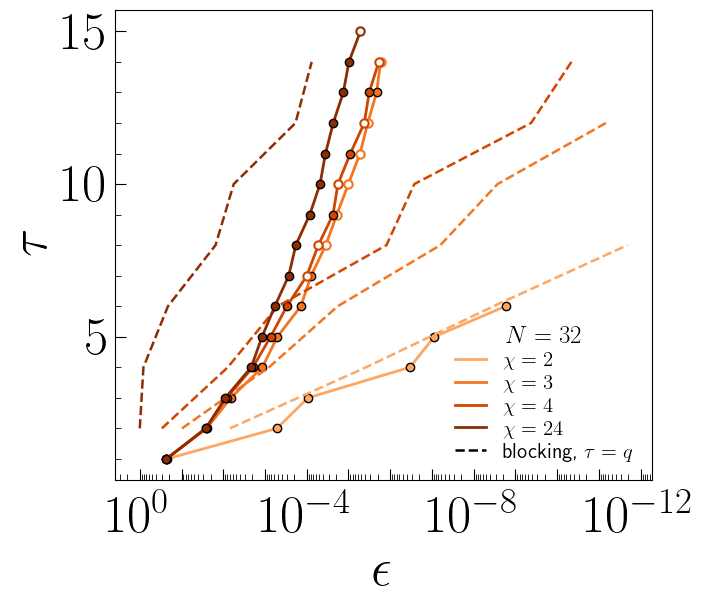

In [14]:
# (8a) XXZ Jz=2.5, N=32: tau vs eps for the target truncated to bond dimension chi = 2, 3, 4 and the full state (chi = 24),
# best run of every depth (xxz_Jz2.5_N32_best.csv, `source` says which run). Filled: finished; hollow: still running.
# Dashed: error of the RG blocking into blocks of q sites (xxz_Jz2.5_N32_blocking.csv), drawn at tau = q; rows at
# roundoff (below_roundoff) dropped.
N = 32
b32 = pd.read_csv(datapath + 'xxz/Jz2.5/xxz_Jz2.5_N32_best.csv')
bl32 = pd.read_csv(datapath + 'xxz/Jz2.5/xxz_Jz2.5_N32_blocking.csv')
bl32 = bl32[~bl32.below_roundoff & (bl32.err > 0) & (bl32.q % 2 == 0)]
chis = sorted(b32.chi.unique())
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
for chi, s in zip(chis, np.linspace(0.4, 0.95, len(chis))):
    d = b32[b32.chi == chi].sort_values('tau')
    c = plt.cm.Oranges(s)
    ax.plot(d.err, d.tau, '-', c=c, lw=MK['lw'], label=rf'$\chi={chi}$')
    f = d.finished
    ax.plot(d.err[f], d.tau[f], 'o', c=c, mec='k', mew=1, ms=MK['ms'] + 1)
    ax.plot(d.err[~f], d.tau[~f], 'o', mfc='white', mec=c, mew=1.5, ms=MK['ms'] + 1)
    b = bl32[bl32.chi == chi].sort_values('q')
    ax.plot(b.err, b.q, '--', c=c, lw=1.8)
ax.plot([], [], 'k--', lw=1.8, label=r'blocking, $\tau=q$')
tau_eps_axes(ax)
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(          # 12 decades: label every fourth
    lambda x, pos: rf'$10^{{{int(round(np.log10(x)))}}}$' if int(round(np.log10(x))) % 4 == 0 else ''))
ax.legend(frameon=False, fontsize=15, loc='lower right', handlelength=1.5, labelspacing=0.2, ncol=1, columnspacing=0.8,
          title=r'$N=32$', title_fontsize=18)
plt.savefig(resultspath + 'xxz_N32_chi.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'xxz_N32_chi.png', bbox_inches='tight', dpi=300)


In [ ]:
# (8b) XXZ Jz=2.5, N=32, chi=4 target: depths 7 and 8 before (lineage, converged by gradtol) and after improving the
# convergence (top-down: the tau=9 circuit with 2 or 1 layers dropped, then optimized; still running).
# Line: the chi=4 curve of (8a), which uses the improved points.
dd = pd.read_csv(datapath + 'xxz/Jz2.5/xxz_chi4_N32_T7T8_dropdown_summary.csv')
pre, post = dd[dd.source.str.contains('pre')], dd[dd.source.str.contains('post')]
d4 = b32[b32.chi == 4].sort_values('tau')
c = plt.cm.Oranges(0.75)
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
ax.plot(d4.err, d4.tau, '-', c=c, lw=MK['lw'], zorder=1)
ax.plot(d4.err[d4.finished], d4.tau[d4.finished], 'o', c=c, mec='k', mew=1, ms=MK['ms'] + 1, zorder=2)
ax.plot(d4.err[~d4.finished], d4.tau[~d4.finished], 'o', mfc='white', mec=c, mew=1.5, ms=MK['ms'] + 1, zorder=2)
b4 = bl32[bl32.chi == 4].sort_values('q')
ax.plot(b4.err, b4.q, '--', c=c, lw=1.8, zorder=1, label=r'blocking, $\tau=q$')
ax.plot(pre.err, pre.tau, 's', c='0.6', mec='k', mew=1, ms=MK['ms'] + 3, zorder=3, label='before (lineage)')
ax.plot(post.err, post.tau, 'D', c=c, mec='k', mew=1, ms=MK['ms'] + 3, zorder=3, label=r'after (top-down from $\tau=9$)')
for (_, a), (_, b) in zip(pre.sort_values('tau').iterrows(), post.sort_values('tau').iterrows()):
    ax.annotate('', xy=(b.err, b.tau), xytext=(a.err, a.tau),
                arrowprops=dict(arrowstyle='-|>', mutation_scale=14, color='k', lw=1.2, shrinkA=8, shrinkB=8))
    ax.text(np.sqrt(a.err * b.err), a.tau + 0.15, rf'$\times{b.err / a.err:.2f}$', ha='center', va='bottom', fontsize=16)
tau_eps_axes(ax)
ax.set_xlim(2e-3, 5e-6); ax.set_ylim(4.5, 11.5)               # zoom on the two improved depths
ax.xaxis.set_major_formatter(mpl.ticker.LogFormatterMathtext())
ax.legend(frameon=False, fontsize=15, loc='upper left', handlelength=1.2, labelspacing=0.2,
          title=r'$\chi=4$, $N=32$', title_fontsize=18)
plt.savefig(resultspath + 'xxz_N32_chi4_dropdown.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'xxz_N32_chi4_dropdown.png', bbox_inches='tight', dpi=300)


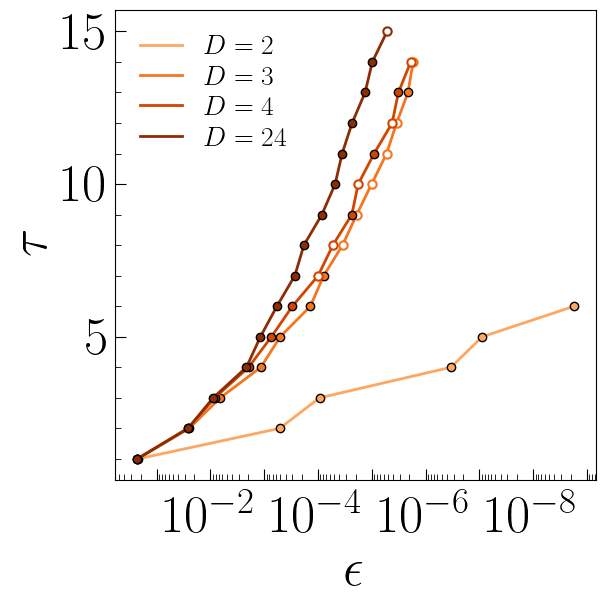

In [18]:
# (8c) as (8a) without the blocking curves: XXZ Jz=2.5, N=32, tau vs eps for chi = 2, 3, 4, 24 (best run of every depth,
# xxz_Jz2.5_N32_best.csv). Filled: finished; hollow: still running.
b32 = pd.read_csv(datapath + 'xxz/Jz2.5/xxz_Jz2.5_N32_best.csv')
chis = sorted(b32.chi.unique())
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
for chi, s in zip(chis, np.linspace(0.4, 0.95, len(chis))):
    d = b32[b32.chi == chi].sort_values('tau')
    c = plt.cm.Oranges(s)
    ax.plot(d.err, d.tau, '-', c=c, lw=MK['lw'], label=rf'$D={chi}$')
    f = d.finished
    ax.plot(d.err[f], d.tau[f], 'o', c=c, mec='k', mew=1, ms=MK['ms'] + 1)
    ax.plot(d.err[~f], d.tau[~f], 'o', mfc='white', mec=c, mew=1.5, ms=MK['ms'] + 1)
tau_eps_axes(ax)
ax.legend(frameon=False, fontsize=20, loc='upper left', handlelength=1.5, labelspacing=0.2, title_fontsize=18)
plt.savefig(resultspath + 'xxz_N32_chi_noblocking.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'xxz_N32_chi_noblocking.png', bbox_inches='tight', dpi=300)


time per iteration [s], Ising g=0.75 (m5_long):
N      60     100    140    180    220    260    300
tau                                                 
1    3.228  3.246  3.262  3.295  3.356  3.357  3.370
2    0.046  0.069  0.099  0.133  0.158  0.180  0.211
3    0.059  0.099  0.147  0.190  0.235  0.268  0.307
4    0.094  0.162  0.224  0.291  0.357  0.425  0.495
5    0.156  0.268  0.392  0.505  0.621  0.703  0.818
6    0.247  0.415  0.592  0.754  0.920  1.073  1.253
7    0.341  0.554  0.796  1.023  1.244  1.466  1.752
8    0.420  0.691  1.000  1.350  1.679  1.973  2.299
9    0.491  0.836  1.264  1.579  1.618  1.715  2.036
10   0.568  1.012  1.260  1.320  1.723    NaN    NaN
11   0.696  1.215  1.218    NaN    NaN    NaN    NaN
12   0.701  1.130    NaN    NaN    NaN    NaN    NaN
13   0.585  1.019    NaN    NaN    NaN    NaN    NaN
14   0.599  1.159    NaN    NaN    NaN    NaN    NaN
15   1.063  2.026    NaN    NaN    NaN    NaN    NaN
time per iteration [s], XXZ Jz=2.5 (m20_long):
N   

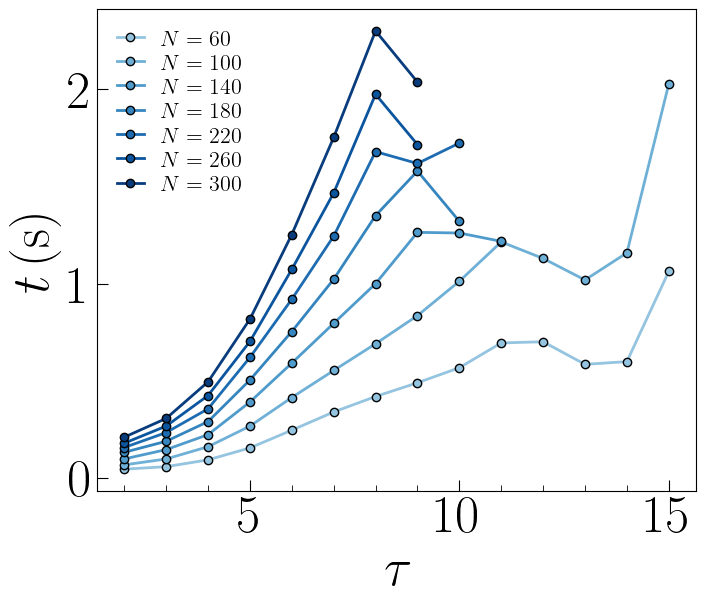

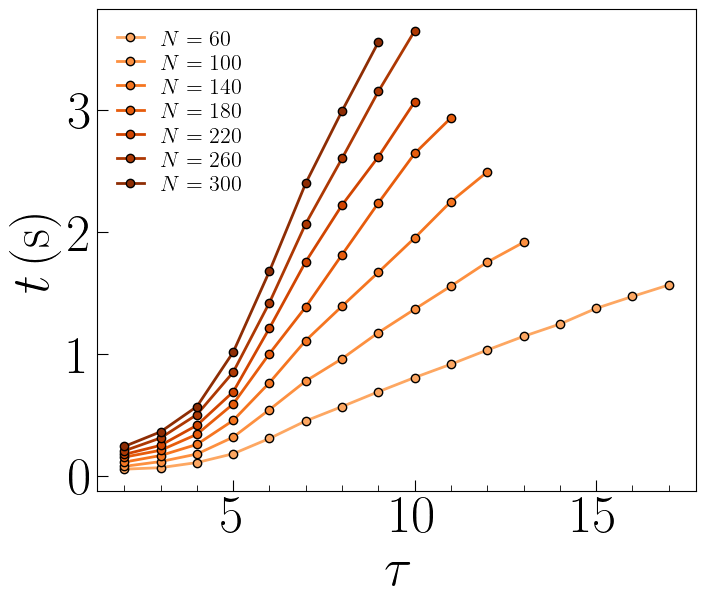

In [16]:
# (9) Time per iteration, time1iter = time / niter (extract_data of invertTruncData copy.jl), of the sequential runs
# Ising g=0.75 (m5_long) and XXZ Jz=2.5 (m20_long, df.csv written with the same extract_data).
# tau = 1 is left out: its few iterations include the compilation time (~4 s), not the cost of an iteration.
t_ising = pd.read_csv(datapath + 'ising/g0.75/m5_long/df.csv').sort_values(['N', 'tau'])
t_xxz   = pd.read_csv(datapath + 'xxz/Jz2.5/m20_long/df.csv').sort_values(['N', 'tau'])
print('time per iteration [s], Ising g=0.75 (m5_long):')
print(t_ising.pivot(index='tau', columns='N', values='time1iter').round(3).to_string())
print('time per iteration [s], XXZ Jz=2.5 (m20_long):')
print(t_xxz.pivot(index='tau', columns='N', values='time1iter').round(3).to_string())

for df, name, cmap in [(t_ising, 'ising', plt.cm.Blues), (t_xxz, 'xxz', plt.cm.Oranges)]:
    fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
    Ns = sorted(df.N.unique())
    for N, s in zip(Ns, np.linspace(0.4, 0.95, len(Ns))):
        d = df[(df.N == N) & (df.tau >= 2)]
        ax.plot(d.tau, d.time1iter, '-o', c=cmap(s), mec='k', mew=1, lw=2, ms=6, label=rf'$N={N}$')
    ax.set_xlabel(r'$\tau$')
    ax.set_ylabel(r'$t\,(\mathrm{s})$')
    ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(5)); ax.xaxis.set_minor_locator(mpl.ticker.MultipleLocator(1))
    ax.tick_params(which='both', direction='in'); ax.tick_params(which='major', length=8); ax.tick_params(which='minor', length=4)
    ax.legend(frameon=False, fontsize=16, loc='upper left', handlelength=1.2, labelspacing=0.2)
    plt.savefig(resultspath + f'time1iter_{name}.pdf', bbox_inches='tight')
    plt.savefig(resultspath + f'time1iter_{name}.png', bbox_inches='tight', dpi=300)


(10) Jz=2.5: xi = 1.586 (K fit on r = 2..28), 28 depths, tau = 1..28
(10) Jz=10: xi = 0.513 (K fit on r = 2..14), 28 depths, tau = 1..28
(10) Jz=20: xi = 0.371 (K fit on r = 2..10), 28 depths, tau = 1..28
(10) Jz=50: xi = 0.265 (K fit on r = 2..7), 28 depths, tau = 1..28


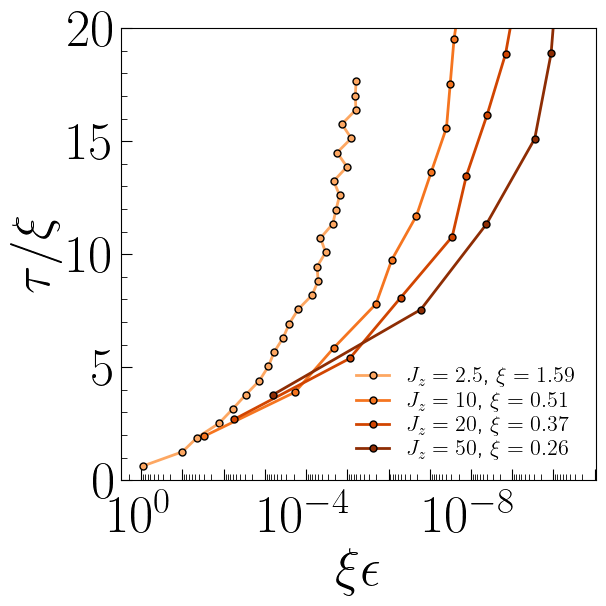

In [11]:
# (10) XXZ, N=100, parallel runs: tau/xi vs xi*eps for Jz = 2.5 (chi=36), 10, 20, 50 (chi=20), final (latest) error of
# every depth. xi from the decay of the connected two-site correlations of each target (connected_K.jl, K_N100.csv):
# K(r) ~ exp(-2r/xi), fitted on r >= 2 down to K = 1e-26 (above the arithmetic floor ~1e-29), both parities of r together.
# All depths are drawn; the tau/xi axis is cut at 20 (the saturated walls of the large Jz run far above it).
N = 100
runs = [(2.5, it_xxz[36], 'xxz/Jz2.5/sweeps/chi36/'), (10, None, 'xxz/Jz10/chi20/'),
        (20, None, 'xxz/Jz20/chi20/'), (50, None, 'xxz/Jz50/chi20/')]
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
for (Jz, it, folder), s in zip(runs, np.linspace(0.4, 0.95, len(runs))):
    if it is None:
        it = pd.read_csv(datapath + folder + 'parallel/df_iters.csv')
    fin = it[it.N == N].dropna(subset=['err']).sort_values('M').groupby('tau').last().reset_index().sort_values('tau')
    K = pd.read_csv(datapath + folder + f'K_N{N}.csv')
    k = K[(K.r >= 2) & (K.K > 1e-26)]
    xi = -2 / np.polyfit(k.r, np.log(k.K), 1)[0]
    print(f'(10) Jz={Jz}: xi = {xi:.3f} (K fit on r = {k.r.min()}..{k.r.max()}), {len(fin)} depths, '
          f'tau = 1..{fin.tau.max()}')
    c = plt.cm.Oranges(s)
    ax.plot(xi * fin.err, fin.tau / (xi), '-o', c=c, mec='k', mew=1, lw=MK['lw'], ms=MK['ms'], label=rf'$J_z={Jz:g}$, $\xi={xi:.2f}$')
tau_eps_axes(ax, ymajor=5)
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(          # 10 decades: label every fourth
    lambda x, pos: rf'$10^{{{int(round(np.log10(x)))}}}$' if int(round(np.log10(x))) % 4 == 0 else ''))
ax.set_xlabel(r'$\xi\epsilon$')
ax.set_ylabel(r'$\tau/\xi$')
ax.set_ylim(0, 20)
ax.legend(frameon=False, fontsize=16, loc='lower right', handlelength=1.5, labelspacing=0.2)
plt.savefig(resultspath + 'xxz_Jz_tau_over_xi.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'xxz_Jz_tau_over_xi.png', bbox_inches='tight', dpi=300)


In [ ]:
# (11) XXZ Jz=2.5, N=100, tau=14, parallel: gradient norm at every iteration for maxrank chi = 24 and 36
# (normgradhistory of sweeps/chi{24,36}/parallel/N100_T14.jld2, exported to gradhist_N100_T14.csv).
# At chi = 24 the cut runs through (near-)degenerate singular values and the SVD pullback blows up: spikes up to |grad| ~ 60;
# at chi = 36 the history stays smooth (max ~ 0.1 after the first iterations).
gh = pd.read_csv(datapath + 'xxz/Jz2.5/sweeps/gradhist_N100_T14.csv')
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
for chi, c, z in [(24, plt.cm.Oranges(0.5), 2), (36, plt.cm.Oranges(0.95), 3)]:
    d = gh[gh.chi == chi]
    ax.plot(d.iter, d.gradnorm, '-', c=c, lw=0.8, zorder=z, label=rf'$\chi={chi}$')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'$M$')
ax.set_ylabel(r'$\|\nabla f\|$')
log_ticks(ax)
ax.xaxis.set_major_formatter(even_decades)
ax.yaxis.set_major_formatter(even_decades)
ax.tick_params(axis='x', which='major', pad=12)
ax.legend(frameon=False, fontsize=18, loc='lower left', handlelength=1.5, labelspacing=0.2,
          title=r'$N=100$, $\tau=14$', title_fontsize=18)
for l in ax.get_legend().get_lines(): l.set_linewidth(3)
plt.savefig(resultspath + 'xxz_gradnorm_chi24_chi36.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'xxz_gradnorm_chi24_chi36.png', bbox_inches='tight', dpi=300)


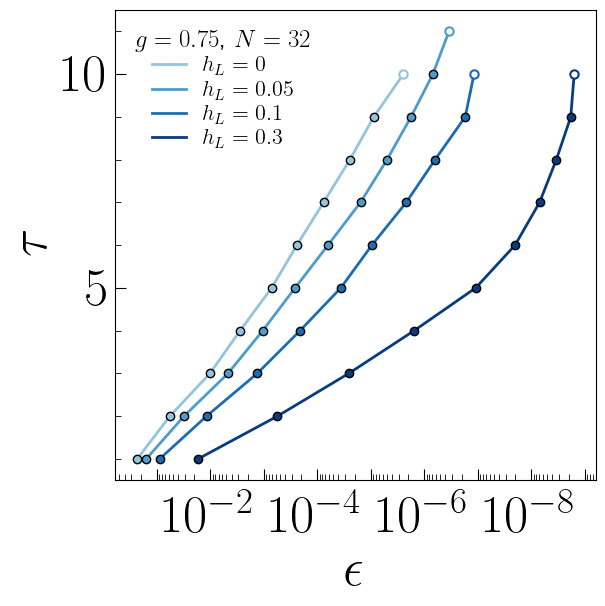

In [29]:
# (12) Ising g=0.75 with a longitudinal field hL, N=32: tau vs eps for every hL (ising_transverse_longitudinal_N32.csv,
# rows with best = True: one per depth). Filled: finished; hollow: stopped before finishing (last checkpoint).
tl = pd.read_csv(datapath + 'ising/ising_transverse_longitudinal_N32.csv')
tl = tl[np.isclose(tl.g, 0.75) & tl.best]
hLs = sorted(tl.hL.unique())
hLs = [h for h in hLs if np.isclose(h, 0.0) or h >= 0.05]          # drop the very small hL = 0.001 (no effect on the error)
fig, ax = plt.subplots(figsize=FIGSIZE, layout='tight')
for hL, s in zip(hLs, np.linspace(0.4, 0.95, len(hLs))):
    d = tl[tl.hL == hL].sort_values('tau')
    c = plt.cm.Blues(s)
    ax.plot(d.err, d.tau, '-', c=c, lw=MK['lw'], label=rf'$h_L={hL:g}$')
    f = d.finished.astype(bool)
    ax.plot(d.err[f], d.tau[f], 'o', c=c, mec='k', mew=1, ms=MK['ms'] + 1)
    ax.plot(d.err[~f], d.tau[~f], 'o', mfc='white', mec=c, mew=1.5, ms=MK['ms'] + 1)
tau_eps_axes(ax)
ax.legend(frameon=False, fontsize=16, loc='upper left', handlelength=1.5, labelspacing=0.2,
          title=r'$g=0.75$, $N=32$', title_fontsize=18)
plt.savefig(resultspath + 'ising_hL_N32.pdf', bbox_inches='tight')
plt.savefig(resultspath + 'ising_hL_N32.png', bbox_inches='tight', dpi=300)
